In [ ]:
# cell2loc_env

import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict, Counter
from scipy.cluster import hierarchy
from matplotlib import cm
import matplotlib.colors as mcolors
from sklearn import preprocessing
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

import sys
import new_misc_code as nmc 

cmap = sns.color_palette( "ch:start=.2,rot=-.3", n_colors=1_000)


In [ ]:
save_figure_path = './Leptin_manuscript/individual_fig/'
save_obj_path = './Leptin_manuscript/individual_fig/dataObj/'

In [3]:
# Choose 5 colors (can use any palette, e.g., tab10)
stage_order = ['ob', 'leptinARC3h', 'leptinARC27h', 'leptinARC75h', 'wt']
stage_color_dict = dict(ob="#e04516", leptinARC3h="#8dc9d0", leptinARC27h="#23c6ea", leptinARC75h="#2127d9", wt="#22d062")

stage_order_PVH = ['ob', 'leptinPVH3h', 'leptinPVH27h', 'leptinPVH75h', 'wt']
stage_color_PVH_dict = dict(ob="#e04516", leptinPVH3h="#cdd781", leptinPVH27h="#B4B415", leptinPVH75h="#f1ca07", wt="#22d062")

# Figure 1

### 1c ARC Hotspot Module
Hotspot module analysis

In [ ]:
import pickle as pkl
import hotspot
import math

hs = nmc.load_obj( "hotspot_v2.pkl")
adata = sc.read(save_figure_path + 'dataObj/adata_seurat_111621_scvelo_hotspot_plotting.h5ad')
hs.module_scores = pd.DataFrame( adata.obsm['module_scores'], index=adata.obs_names, columns=range(adata.obsm['module_scores'].shape[1]) )
hs.modules = adata.uns['modules']
umap = adata.obsm['X_umap']

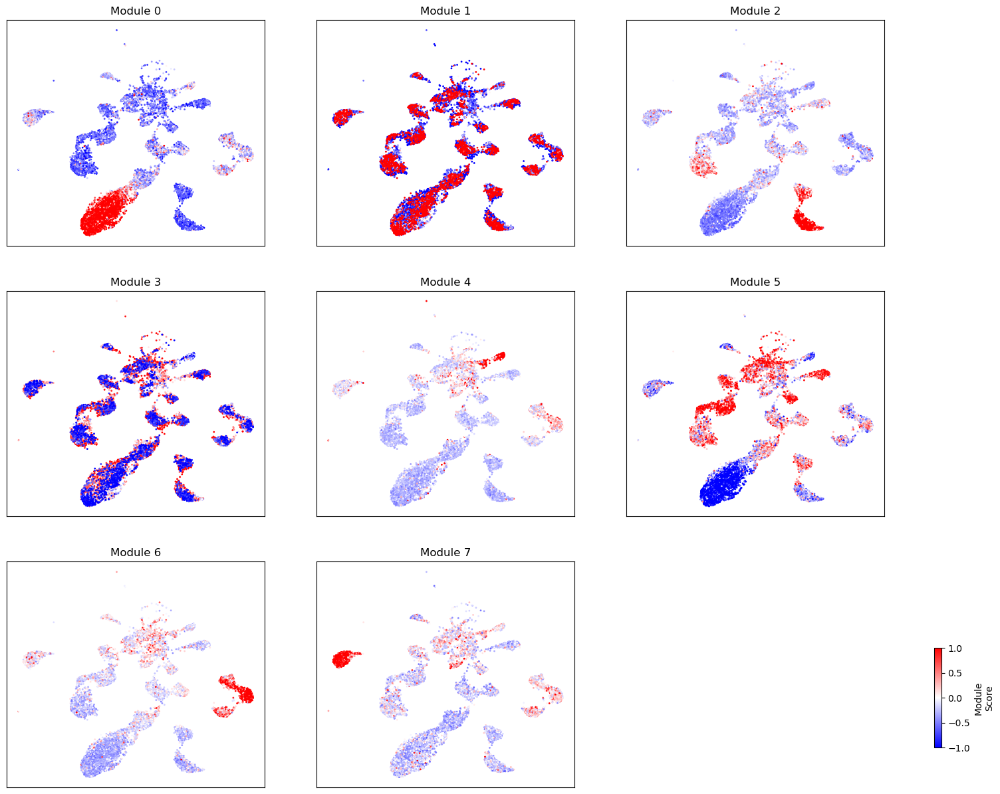

In [5]:
# UMAP plot of module scores
n    = adata.obsm['module_scores'].shape[1]
hs.module_scores = pd.DataFrame( adata.obsm['module_scores'], index=adata.obs_names, columns=range(n))
cols = round( math.sqrt( n))
rows = math.ceil( n / cols)
size = cols * rows

fig, axs = plt.subplots( rows, cols, figsize=(rows*5,cols*5))
cax = fig.add_axes(
    [.95, .15, .007, .1]
)
for itr, (ax, mod) in enumerate( zip( axs.ravel(), hs.module_scores.columns)):
    ax.set_facecolor( 'white')
    scp = hs.module_scores[mod]
    vmin = -1
    vmax = 1
    plt.sca(ax)
    scp = plt.scatter(
        umap[:,0], umap[:,1],
        s=1, c=scp, vmin=vmin, vmax=vmax,
        rasterized=True, cmap='bwr')
    plt.xticks([])
    plt.yticks([])
    plt.title("Module {}".format(mod))
# clear rest of graphs
for ii in range( itr+1, size):
    ax = axs.flatten()[ii]
    ax.axis('off')
        
plt.subplots_adjust(hspace=0.2)
plt.colorbar(scp, cax=cax, label='Module\nScore')
plt.subplots_adjust(left=0.02, right=0.9)
#plt.show()
plt.savefig(save_figure_path + "Fig.1/Fig1c_supp_ARC_hotspot_module_scores_umap.pdf", dpi=300)

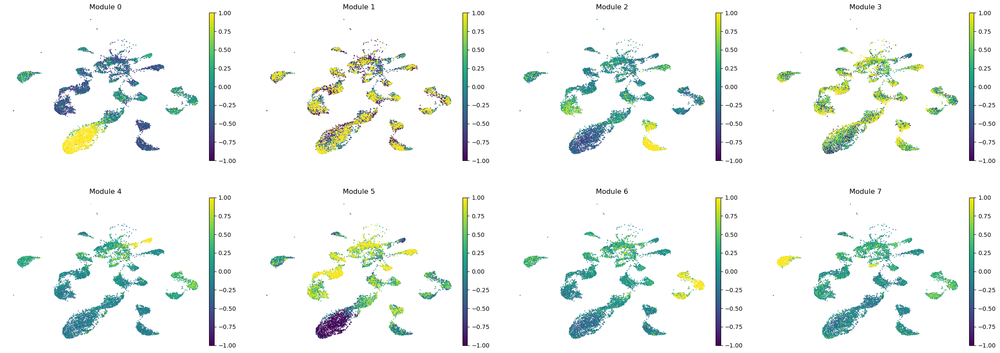

In [6]:
# Alternate way to plot
module_cols = []
for c in hs.module_scores.columns:
    key = f"Module {c}"
    adata.obs[key] = hs.module_scores[c]
    module_cols.append(key)
    
sc.pl.umap(adata, color=module_cols, frameon=False, vmin=-1, vmax=1)

In [7]:
# get all modules in a dataframe
all_mods = hs.results.join(adata.uns['modules'])
all_mods.dropna( inplace=True)
# drop non assigned genes
all_mods = all_mods[all_mods['Module']!=-1.0]
all_mods.shape

(427, 5)

In [8]:
adata.obs['clusters'] = adata.obs['clusters'].astype(str)
major_clusts =['0','1','2','3','4','5','6','7','8','10',
                                  '11','12','13','14','16','17','18','19','22']
stage_dict = {'ob':'ob', 'leptinARC3h':'leptinARC3h', 'leptinARC24h':'leptinARC27h', 'leptinARC72h':'leptinARC75h', 'wt':'wt'}
adata.obs['condition'] = adata.obs['condition'].map(stage_dict)
gene_names = adata.var_names.values

In [10]:
def member_test( A, B):
    b = set(B)
    return( [x in b for x in A])

# dataframe to hold cluster stage module expression
csme = pd.DataFrame([])
# loop through majors
for clust_itr in major_clusts:
    if( clust_itr=='Poor-Quality'):
        continue
    print( clust_itr)
    # take slice from adata data set
    adata_itr1 = adata[adata.obs['clusters']==clust_itr]
    # loop through stages
    for stage_itr in stage_order:
        stage_mk = adata_itr1.obs['condition']==stage_itr
        # only want to look at stages with over 10 cells in a cluster
        if( sum( stage_mk)<10):
            continue
        adata_itr2 = adata_itr1[stage_mk]
        ind_nm = f"{stage_itr}_{clust_itr}"
#         print( f"{ind_nm} shape is {adata_itr2.shape}")
        # loop through modules
        for mod_itr in all_mods['Module'].unique():
            if( int(mod_itr)==-1):
                continue
            mod_gene_mk = all_mods['Module']==mod_itr
            mod_genes = all_mods.index.values[mod_gene_mk]
            adata_gene_mk = np.array(member_test( gene_names, mod_genes))
            gene_csr = adata_itr2[:,adata_gene_mk].X
            if( gene_csr.sum(0).sum()==0.0):
                print( f"nothing in {ind_nm}")
                csme.loc[ind_nm,f"Module-{str(int(mod_itr))}"] = 0.0
            else:
                gene_mean = gene_csr.mean(0)
                csme.loc[ind_nm,f"Module-{str(int(mod_itr))}"] = np.mean( gene_mean)

0
1
2
3
4
5
6
7
8
10
11
12
13
14
16
17
18
19
22


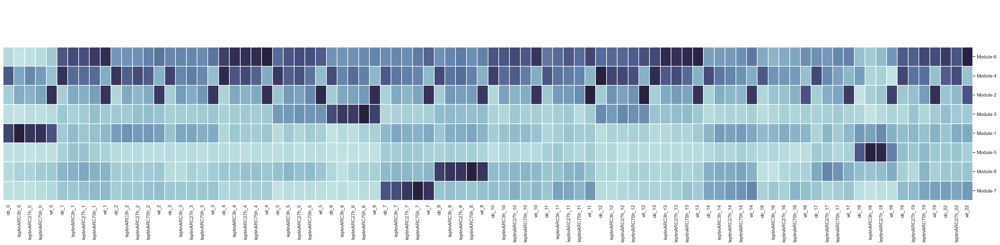

In [13]:
cmap = sns.color_palette( "ch:start=.2,rot=-.3", n_colors=1000)
sns.set(rc={'axes.facecolor':'white', 'figure.facecolor':'white'})
#                                                                                                                                                     left_rigth,up/down,
g = sns.clustermap( csme.T, col_cluster=False, standard_scale=0, figsize=(40,8), cmap=cmap, yticklabels=csme.columns.values, linewidths=0.025, cbar_pos=(0.25, 0.925, 0.325, 0.05), 
                    cbar_kws={"orientation": "horizontal"})
g.ax_row_dendrogram.set_visible(False)
g.cax.set_visible(False)
plt.setp( g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0);
plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + "Fig.1/Fig1c_ARC_hotspot_module_scores_umap.pdf", dpi=300)


### 1c ARC Hospot Module with scale


0
1
2
3
4
5
6
7
8
10
11
12
13
14
16
17
18
19
22


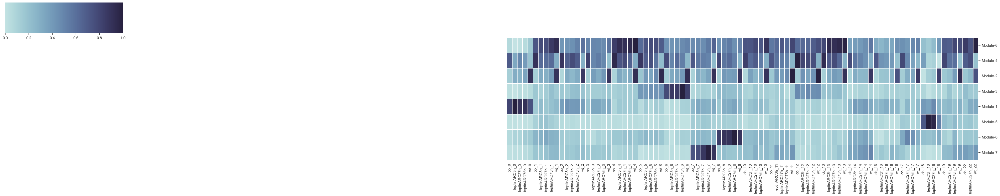

In [ ]:
import pickle as pkl
import hotspot
import math

hs = nmc.load_obj("hotspot_v2.pkl")
adata = sc.read(save_figure_path + 'dataObj/adata_seurat_111621_scvelo_hotspot_plotting.h5ad')
hs.module_scores = pd.DataFrame( adata.obsm['module_scores'], index=adata.obs_names, columns=range(adata.obsm['module_scores'].shape[1]) )
hs.modules = adata.uns['modules']
umap = adata.obsm['X_umap']

# UMAP plot of module scores
n    = adata.obsm['module_scores'].shape[1]
hs.module_scores = pd.DataFrame( adata.obsm['module_scores'], index=adata.obs_names, columns=range(n))
cols = round( math.sqrt( n))
rows = math.ceil( n / cols)
size = cols * rows

#plt.show()
#plt.savefig(save_figure_path + "Fig.1/Fig1c_supp_ARC_hotspot_module_scores_umap.pdf", dpi=300)
# get all modules in a dataframe
all_mods = hs.results.join(adata.uns['modules'])
all_mods.dropna( inplace=True)
# drop non assigned genes
all_mods = all_mods[all_mods['Module']!=-1.0]
all_mods.shape

def member_test( A, B):
    b = set(B)
    return( [x in b for x in A])

adata.obs['clusters'] = adata.obs['clusters'].astype(str)
major_clusts =['0','1','2','3','4','5','6','7','8','10',
                                  '11','12','13','14','16','17','18','19','22']
stage_dict = {'ob':'ob', 'leptinARC3h':'leptinARC3h', 'leptinARC24h':'leptinARC27h', 'leptinARC72h':'leptinARC75h', 'wt':'wt'}
adata.obs['condition'] = adata.obs['condition'].map(stage_dict)
gene_names = adata.var_names.values

# dataframe to hold cluster stage module expression
csme = pd.DataFrame([])
# loop through majors
for clust_itr in major_clusts:
    if( clust_itr=='Poor-Quality'):
        continue
    print( clust_itr)
    # take slice from adata data set
    adata_itr1 = adata[adata.obs['clusters']==clust_itr]
    # loop through stages
    for stage_itr in stage_order:
        stage_mk = adata_itr1.obs['condition']==stage_itr
        # only want to look at stages with over 10 cells in a cluster
        if( sum( stage_mk)<10):
            continue
        adata_itr2 = adata_itr1[stage_mk]
        ind_nm = f"{stage_itr}_{clust_itr}"
#         print( f"{ind_nm} shape is {adata_itr2.shape}")
        # loop through modules
        for mod_itr in all_mods['Module'].unique():
            if( int(mod_itr)==-1):
                continue
            mod_gene_mk = all_mods['Module']==mod_itr
            mod_genes = all_mods.index.values[mod_gene_mk]
            adata_gene_mk = np.array(member_test( gene_names, mod_genes))
            gene_csr = adata_itr2[:,adata_gene_mk].X
            if( gene_csr.sum(0).sum()==0.0):
                print( f"nothing in {ind_nm}")
                csme.loc[ind_nm,f"Module-{str(int(mod_itr))}"] = 0.0
            else:
                gene_mean = gene_csr.mean(0)
                csme.loc[ind_nm,f"Module-{str(int(mod_itr))}"] = np.mean( gene_mean)

cmap = sns.color_palette( "ch:start=.2,rot=-.3", n_colors=1000)
sns.set(rc={'axes.facecolor':'white', 'figure.facecolor':'white'})
#                                                                                                                                                     left_rigth,up/down,
g = sns.clustermap( csme.T, col_cluster=False, standard_scale=0, figsize=(40,8), cmap=cmap, yticklabels=csme.columns.values, linewidths=0.025, cbar_pos=(0.25, 0.925, 0.325, 0.05), 
                    cbar_kws={"orientation": "horizontal"})
g.ax_row_dendrogram.set_visible(False)
g.cax.set_visible(True)
plt.setp( g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0);
plt.tight_layout()
plt.savefig(save_figure_path + "Fig1/scale/Fig1c_ARC_hotspot_scale_module_scores_umap.pdf", dpi=300)


#### Go term analysis

In [12]:
gm_df = pd.read_csv( save_figure_path + "dataObj/fig1c_GO_dataframe_vs_Hotspot-modules_ARC_v2.csv", index_col=0)

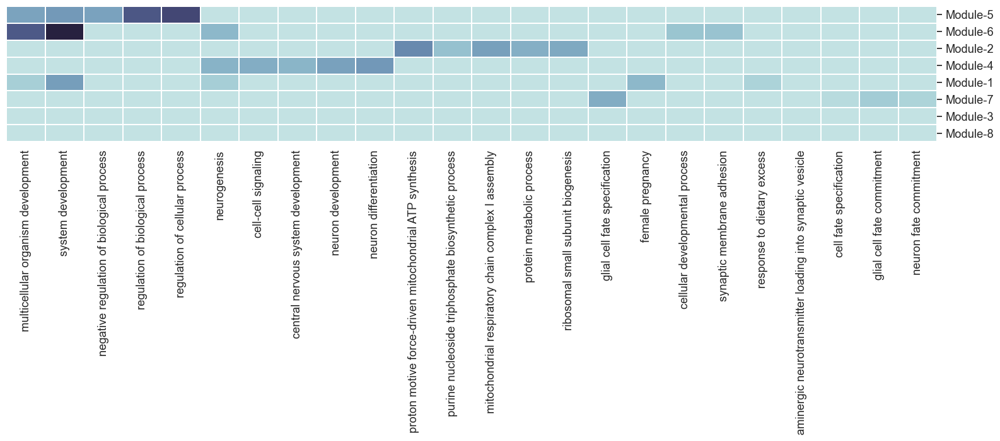

In [37]:
sns.set(font_scale=1.20)
g = sns.clustermap( gm_df, col_cluster=True, figsize=(20,8), cmap=cmap, cbar_pos=(0.15, 0.825, 0.525, 0.012), 
                    cbar_kws={"orientation": "horizontal"}, linewidths=0.025)#, "ticks":-np.log10([1,0.05,0.005])})#, "ticklabels":["1.0", "0.05", "0.005"]})
g.ax_col_dendrogram.set_visible(False)
g.ax_row_dendrogram.set_visible(False)
plt.setp( g.ax_heatmap.xaxis.get_majorticklabels(), rotation=90);
plt.setp( g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0);
g.cax.set_visible(False)
plt.tight_layout()
plt.savefig(save_figure_path + "fig.1/fig1c_hotspot_GOs-vs-modules_ARC_v2.pdf", format='pdf', dpi=300)
#plt.show()

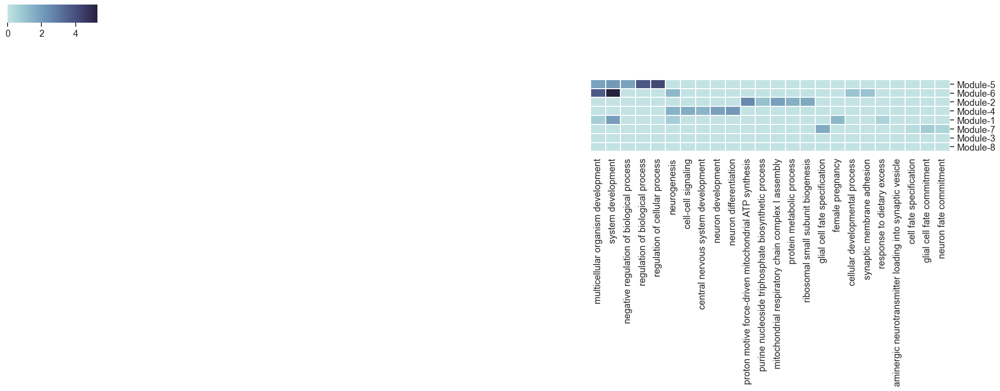

In [ ]:
# to get the colorbar, need to set cax visible before saving
sns.set(font_scale=1.20)
g = sns.clustermap( gm_df, col_cluster=True, figsize=(20,8), cmap=cmap, cbar_pos=(0.15, 0.825, 0.525, 0.012), 
                    cbar_kws={"orientation": "horizontal"}, linewidths=0.025)#, "ticks":-np.log10([1,0.05,0.005])})#, "ticklabels":["1.0", "0.05", "0.005"]})
g.ax_col_dendrogram.set_visible(False)
g.ax_row_dendrogram.set_visible(False)
plt.setp( g.ax_heatmap.xaxis.get_majorticklabels(), rotation=90);
plt.setp( g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0);
g.cax.set_visible(True)
plt.tight_layout()
plt.savefig(save_figure_path + "Fig1/scale/fig1c_hotspot_GOs-vs-modules_ARC_v2.pdf", format='pdf', dpi=300)


### 1d PVH Hotspot Module
Hotspot module analysis

In [ ]:
import pickle as pkl
import hotspot
import math

hs = nmc.load_obj("hotspot_pvh_v3.pkl")
adata = sc.read(save_figure_path + 'dataObj/adata_seurat_PVH_111621_v2_hotspot_plotting.h5ad')
hs.module_scores = pd.DataFrame( adata.obsm['module_scores'], index=adata.obs_names, columns=range(adata.obsm['module_scores'].shape[1]) )
hs.modules = adata.uns['modules']
umap = adata.obsm['X_umap']


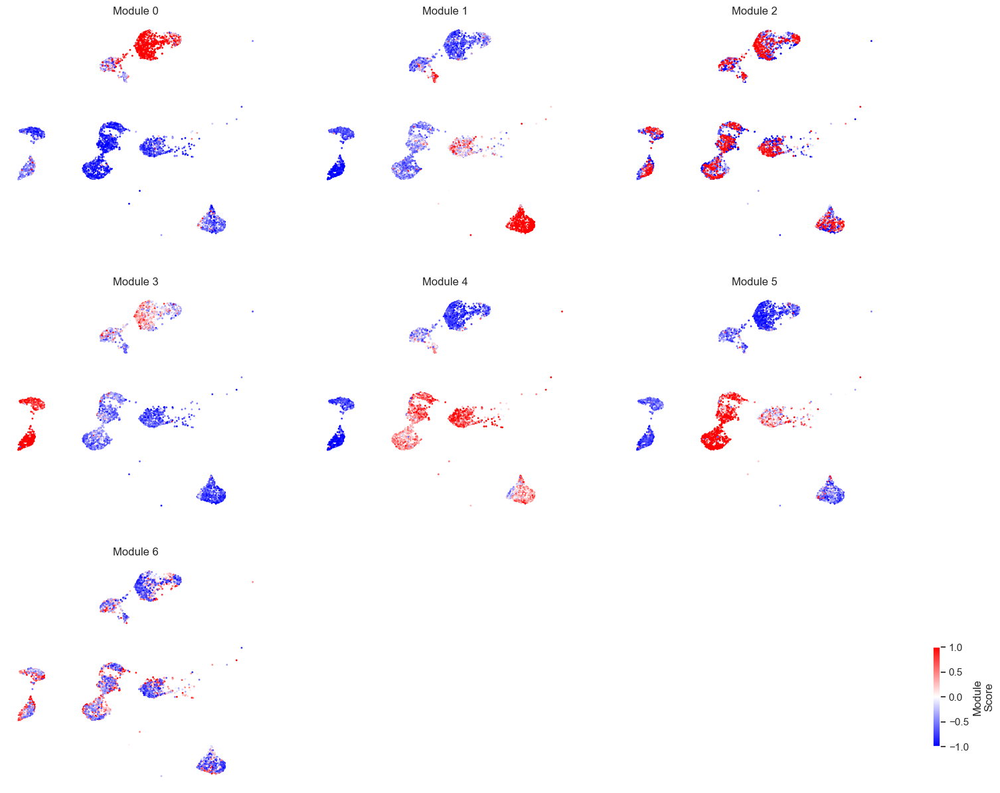

In [ ]:
# UMAP plot of module scores
n    = adata.obsm['module_scores'].shape[1]
hs.module_scores = pd.DataFrame( adata.obsm['module_scores'], index=adata.obs_names, columns=range(n))
cols = round( math.sqrt( n))
rows = math.ceil( n / cols)
size = cols * rows

fig, axs = plt.subplots( rows, cols, figsize=(rows*5,cols*5))
cax = fig.add_axes(
    [.95, .15, .007, .1]
)
for itr, (ax, mod) in enumerate( zip( axs.ravel(), hs.module_scores.columns)):
    ax.set_facecolor( 'white')
    scp = hs.module_scores[mod]
    vmin = -1
    vmax = 1
    plt.sca(ax)
    scp = plt.scatter(
        umap[:,0], umap[:,1],
        s=1, c=scp, vmin=vmin, vmax=vmax,
        rasterized=True, cmap='bwr')
    plt.xticks([])
    plt.yticks([])
    plt.title("Module {}".format(mod))
# clear rest of graphs
for ii in range( itr+1, size):
    ax = axs.flatten()[ii]
    ax.axis('off')
        
plt.subplots_adjust(hspace=0.2)
plt.colorbar(scp, cax=cax, label='Module\nScore')
plt.subplots_adjust(left=0.02, right=0.9)
#plt.show()
plt.savefig(save_figure_path + "Fig.1/Fig1d_supp_PVH_hotspot_module_scores_umap.pdf", dpi=300)

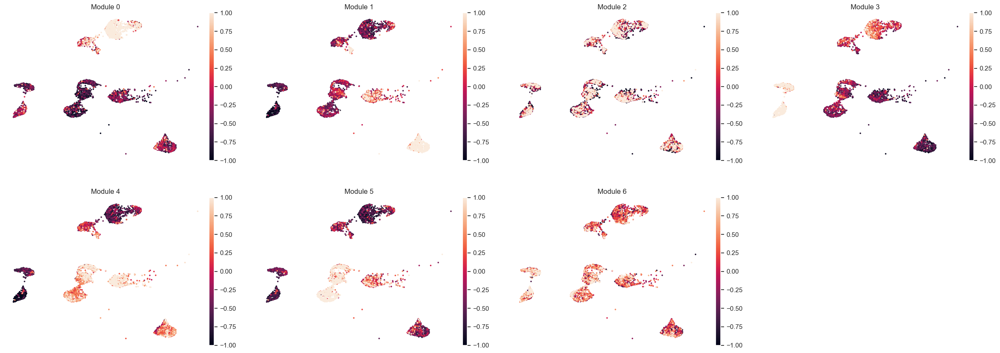

In [17]:
# Alternate way to plot
module_cols = []
for c in hs.module_scores.columns:
    key = f"Module {c}"
    adata.obs[key] = hs.module_scores[c]
    module_cols.append(key)
    
sc.pl.umap(adata, color=module_cols, frameon=False, vmin=-1, vmax=1)

In [18]:
# get all modules in a dataframe
all_mods = hs.results.join(adata.uns['modules'])
all_mods.dropna( inplace=True)
# drop non assigned genes
all_mods = all_mods[all_mods['Module']!=-1.0]
all_mods.shape

(407, 5)

In [19]:
adata.obs['clusters'] = adata.obs['clusters'].astype(str)
major_clusts = ['3',  '6',  '7',  '8', '11', '14', '15', '16', '18', '22']
stage_dict = {'ob':'ob', 'leptinPVH3h':'leptinPVH3h', 'leptinPVH24h':'leptinPVH27h', 'leptinPVH72h':'leptinPVH75h', 'wt':'wt'}
adata.obs['condition'] = adata.obs['condition'].map(stage_dict)
gene_names = adata.var_names.values

In [20]:
def member_test( A, B):
    b = set(B)
    return( [x in b for x in A])

# dataframe to hold cluster stage module expression
csme = pd.DataFrame([])
# loop through majors
for clust_itr in major_clusts:
    if( clust_itr=='Poor-Quality'):
        continue
    print( clust_itr)
    # take slice from adata data set
    adata_itr1 = adata[adata.obs['clusters']==clust_itr]
    # loop through stages
    for stage_itr in stage_order_PVH:
        stage_mk = adata_itr1.obs['condition']==stage_itr
        # only want to look at stages with over 10 cells in a cluster
        if( sum( stage_mk)<10):
            continue
        adata_itr2 = adata_itr1[stage_mk]
        ind_nm = f"{stage_itr}_{clust_itr}"
#         print( f"{ind_nm} shape is {adata_itr2.shape}")
        # loop through modules
        for mod_itr in all_mods['Module'].unique():
            if( int(mod_itr)==-1):
                continue
            mod_gene_mk = all_mods['Module']==mod_itr
            mod_genes = all_mods.index.values[mod_gene_mk]
            adata_gene_mk = np.array(member_test( gene_names, mod_genes))
            gene_csr = adata_itr2[:,adata_gene_mk].X
            if( gene_csr.sum(0).sum()==0.0):
                print( f"nothing in {ind_nm}")
                csme.loc[ind_nm,f"Module-{str(int(mod_itr))}"] = 0.0
            else:
                gene_mean = gene_csr.mean(0)
                csme.loc[ind_nm,f"Module-{str(int(mod_itr))}"] = np.mean( gene_mean)

3
6
7
8
11
14
15
16
18
22


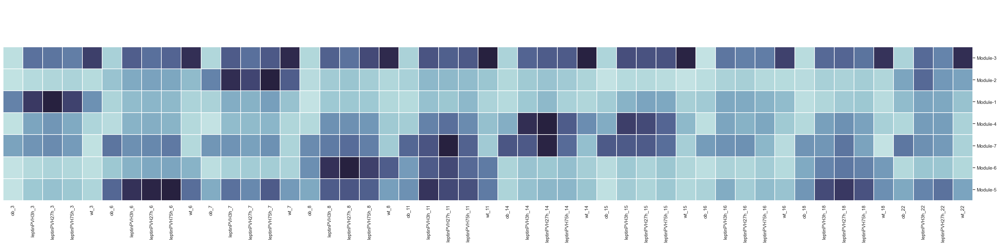

In [23]:
cmap = sns.color_palette( "ch:start=.2,rot=-.3", n_colors=1000)
sns.set(rc={'axes.facecolor':'white', 'figure.facecolor':'white'})
#                                                                                                                                                     left_rigth,up/down,
g = sns.clustermap( csme.T, col_cluster=False, standard_scale=0, figsize=(40,8), 
                   cmap=cmap, yticklabels=csme.columns.values, linewidths=0.025, cbar_pos=(0.25, 0.925, 0.325, 0.05), 
                    cbar_kws={"orientation": "horizontal"})
g.ax_row_dendrogram.set_visible(False)
g.cax.set_visible(False)
plt.setp( g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0);
plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + "Fig.1/Fig1d_PVH_hotspot_module_scores_umap.pdf", dpi=300)


### 1d PVH Hotspot Module with scale

3
6
7
8
11
14
15
16
18
22


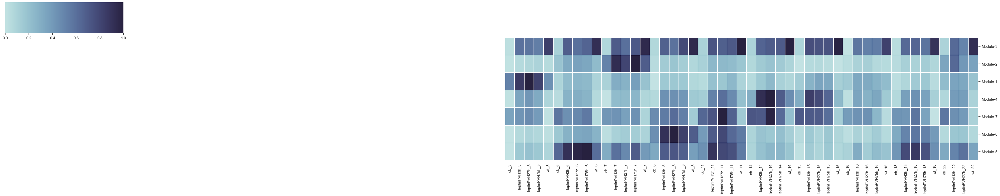

In [ ]:
import pickle as pkl
import hotspot
import math

hs = nmc.load_obj("hotspot_pvh_v3.pkl")
adata = sc.read(save_figure_path + 'dataObj/adata_seurat_PVH_111621_v2_hotspot_plotting.h5ad')
hs.module_scores = pd.DataFrame( adata.obsm['module_scores'], index=adata.obs_names, columns=range(adata.obsm['module_scores'].shape[1]) )
hs.modules = adata.uns['modules']
umap = adata.obsm['X_umap']

# UMAP plot of module scores
n    = adata.obsm['module_scores'].shape[1]
hs.module_scores = pd.DataFrame( adata.obsm['module_scores'], index=adata.obs_names, columns=range(n))
cols = round( math.sqrt( n))
rows = math.ceil( n / cols)
size = cols * rows

module_cols = []
for c in hs.module_scores.columns:
    key = f"Module {c}"
    adata.obs[key] = hs.module_scores[c]
    module_cols.append(key)

# get all modules in a dataframe
all_mods = hs.results.join(adata.uns['modules'])
all_mods.dropna( inplace=True)
# drop non assigned genes
all_mods = all_mods[all_mods['Module']!=-1.0]
all_mods.shape

adata.obs['clusters'] = adata.obs['clusters'].astype(str)
major_clusts = ['3',  '6',  '7',  '8', '11', '14', '15', '16', '18', '22']
stage_dict = {'ob':'ob', 'leptinPVH3h':'leptinPVH3h', 'leptinPVH24h':'leptinPVH27h', 'leptinPVH72h':'leptinPVH75h', 'wt':'wt'}
adata.obs['condition'] = adata.obs['condition'].map(stage_dict)
gene_names = adata.var_names.values

def member_test( A, B):
    b = set(B)
    return( [x in b for x in A])

# dataframe to hold cluster stage module expression
csme = pd.DataFrame([])
# loop through majors
for clust_itr in major_clusts:
    if( clust_itr=='Poor-Quality'):
        continue
    print( clust_itr)
    # take slice from adata data set
    adata_itr1 = adata[adata.obs['clusters']==clust_itr]
    # loop through stages
    for stage_itr in stage_order_PVH:
        stage_mk = adata_itr1.obs['condition']==stage_itr
        # only want to look at stages with over 10 cells in a cluster
        if( sum( stage_mk)<10):
            continue
        adata_itr2 = adata_itr1[stage_mk]
        ind_nm = f"{stage_itr}_{clust_itr}"
#         print( f"{ind_nm} shape is {adata_itr2.shape}")
        # loop through modules
        for mod_itr in all_mods['Module'].unique():
            if( int(mod_itr)==-1):
                continue
            mod_gene_mk = all_mods['Module']==mod_itr
            mod_genes = all_mods.index.values[mod_gene_mk]
            adata_gene_mk = np.array(member_test( gene_names, mod_genes))
            gene_csr = adata_itr2[:,adata_gene_mk].X
            if( gene_csr.sum(0).sum()==0.0):
                print( f"nothing in {ind_nm}")
                csme.loc[ind_nm,f"Module-{str(int(mod_itr))}"] = 0.0
            else:
                gene_mean = gene_csr.mean(0)
                csme.loc[ind_nm,f"Module-{str(int(mod_itr))}"] = np.mean( gene_mean)

cmap = sns.color_palette( "ch:start=.2,rot=-.3", n_colors=1000)
sns.set(rc={'axes.facecolor':'white', 'figure.facecolor':'white'})
#                                                                                                                                                     left_rigth,up/down,
g = sns.clustermap( csme.T, col_cluster=False, standard_scale=0, figsize=(40,8), 
                   cmap=cmap, yticklabels=csme.columns.values, linewidths=0.025, cbar_pos=(0.25, 0.925, 0.325, 0.05), 
                    cbar_kws={"orientation": "horizontal"})
g.ax_row_dendrogram.set_visible(False)
g.cax.set_visible(True)
plt.setp( g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0);
plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + "Fig1/scale/Fig1d_PVH_hotspot_scale_module_scores_umap.pdf", dpi=300)

#### Go term analysis

In [4]:
gm_df = pd.read_csv(save_figure_path + "dataObj/fig1d_GO_dataframe_vs_Hotspot-modules_PVH_v3.csv", index_col=0)

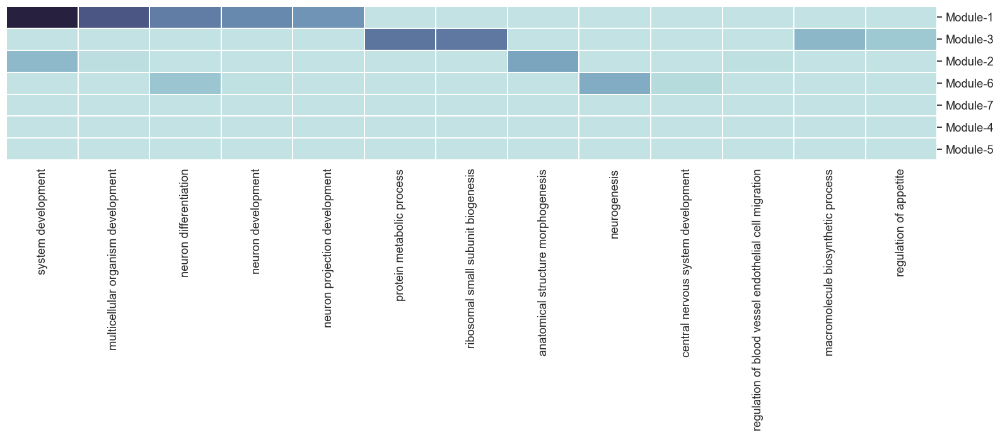

In [ ]:
sns.set(font_scale=1.20)
g = sns.clustermap( gm_df, col_cluster=True, figsize=(20,8), cmap=cmap, cbar_pos=(0.15, 0.825, 0.525, 0.012), 
                    cbar_kws={"orientation": "horizontal"}, linewidths=0.025)#, "ticks":-np.log10([1,0.05,0.005])})#, "ticklabels":["1.0", "0.05", "0.005"]})
g.ax_col_dendrogram.set_visible(False)
g.ax_row_dendrogram.set_visible(False)
plt.setp( g.ax_heatmap.xaxis.get_majorticklabels(), rotation=90);
plt.setp( g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0);
g.cax.set_visible(False)
plt.tight_layout()
plt.savefig(save_figure_path + "Fig1/fig1d_hotspot_GOs-vs-modules_PVH_v3.pdf", format='pdf', dpi=300)
#plt.show()

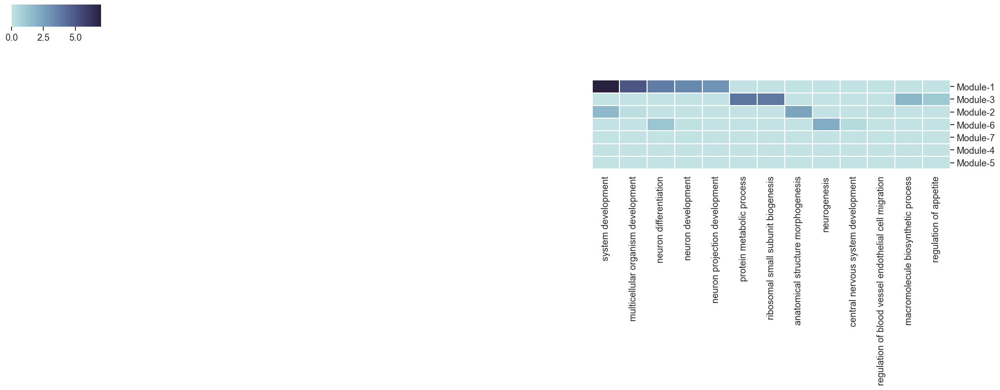

In [ ]:
# to get the scale
sns.set(font_scale=1.20)
g = sns.clustermap( gm_df, col_cluster=True, figsize=(20,8), cmap=cmap, cbar_pos=(0.15, 0.825, 0.525, 0.012), 
                    cbar_kws={"orientation": "horizontal"}, linewidths=0.025)#, "ticks":-np.log10([1,0.05,0.005])})#, "ticklabels":["1.0", "0.05", "0.005"]})
g.ax_col_dendrogram.set_visible(False)
g.ax_row_dendrogram.set_visible(False)
plt.setp( g.ax_heatmap.xaxis.get_majorticklabels(), rotation=90);
plt.setp( g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0);
g.cax.set_visible(True)
plt.tight_layout()
plt.savefig(save_figure_path + "Fig1/scale/fig1d_hotspot_scale_GOs-vs-modules_PVH_v3.pdf", format='pdf', dpi=300)
#plt.show()

### 1e ARC DEGs histogram

In [ ]:
# load the previous analysis results DGE results
logTMMs = nmc.load_obj( "./snRNAseq/data/logTMMs.pkl")
gam_fits = nmc.load_obj( "./snRNAseq/data/AGE_gam_fits_15_grid100.pkl")
sig_genes = {}
for traj_itr, df_itr in logTMMs.items():
    sig_genes[traj_itr] = df_itr.index.values
gene_dict = sig_genes

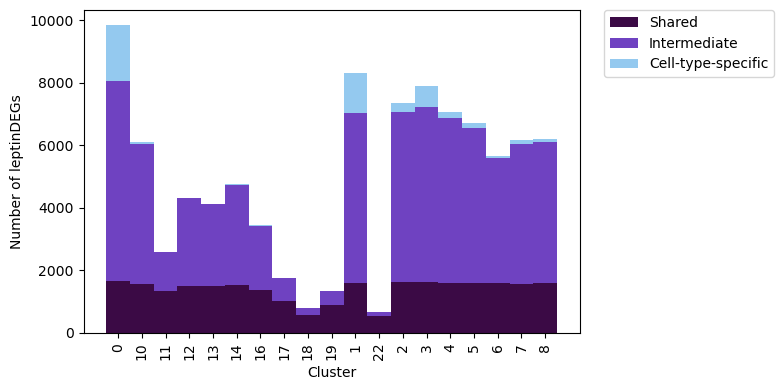

In [8]:
# Plotting the shared vs unique DEGs across clusters
# Step 1: Count gene occurrences across cell types
gene_counts = Counter(g for genes in gene_dict.values() for g in genes)
total_celltypes = len(gene_dict)

# Step 2: Classify each gene by frequency
gene_category = {}
for gene, count in gene_counts.items():
    freq = count / total_celltypes
    if freq <= 0.2: # hard coded
        gene_category[gene] = "unique"
    elif freq >= 0.7: # hard coded
        gene_category[gene] = "shared"
    else:
        gene_category[gene] = "intermediate"

# Step 3: Count gene types per cell type
summary = defaultdict(lambda: {"unique": 0, "shared": 0, "intermediate": 0})

for celltype, genes in gene_dict.items():
    for g in genes:
        cat = gene_category.get(g)
        if cat in summary[celltype]:
            summary[celltype][cat] += 1

# Step 4: Prepare values for plotting
celltypes = list(summary.keys())
unique_vals = [summary[ct]["unique"] for ct in celltypes]
shared_20_vals = [summary[ct]["intermediate"] for ct in celltypes]
shared_70_vals = [summary[ct]["shared"] for ct in celltypes]

# Step 5: Plot stacked bar chart (absolute counts)
x = np.arange(len(celltypes))

plt.figure(figsize=(8, 4))
plt.bar(x, shared_70_vals, width=1, label="Shared", color="#3B0A45")
plt.bar(x, shared_20_vals, width=1, bottom=shared_70_vals, label="Intermediate", color="#6F42C1")
plt.bar(x, unique_vals, width=1, bottom=np.array(shared_70_vals)+np.array(shared_20_vals), label="Cell-type-specific", color="#94C9EF")
plt.xticks(x, celltypes, rotation=90)
plt.ylabel("Number of leptinDEGs")
plt.xlabel("Cluster")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + 'Fig1e_ARC_devGenes_shared.pdf', dpi=800)


In [ ]:
# load the previous analysis results DGE results
logTMMs = nmc.load_obj( "./snRNAseq/data/logTMMs.pkl")
gam_fits = nmc.load_obj( "./snRNAseq/data/AGE_gam_fits_15_grid100.pkl")
sig_genes = {}
for traj_itr, df_itr in logTMMs.items():
    sig_genes[traj_itr] = df_itr.index.values
gene_dict = sig_genes

### 1f ARC Gene Trend Heatmap

In [ ]:
# load data for ARC
adata = sc.read( "adata_seurat_111621_scvelo.h5ad")
adata = adata[adata.obs['clusters'].isin(['0','1','2','3','4','5','6','7','8','10',
                                  '11','12','13','14','16','17','18','19','22'])]

logTMMs = nmc.load_obj( "./snRNAseq/data/logTMMs.pkl")
gam_fits = nmc.load_obj( "./snRNAseq/data/AGE_gam_fits_15_grid100.pkl")

all_goods_df = pd.concat( list( gam_fits.values()), keys=list(gam_fits.keys()))
all_goods_df.index.names = ['cluster', 'gene']

# get highly variable genes
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
hvg_genes = adata.var_names[adata.var.highly_variable]

# filter all_goods_df to only include highly variable genes
second_level_index = all_goods_df.index.get_level_values('gene')
intersection = list(set(second_level_index).intersection(hvg_genes))
all_goods_df_hvg = all_goods_df.loc[(slice(None), intersection), :]

go_df = all_goods_df_hvg

In [27]:
# cluster the gene trends to get row colors
temp_ax = sns.clustermap(
    all_goods_df_hvg,
    metric='euclidean',
    method='ward',
    col_cluster=False,
    row_cluster=True,
    cmap=cmap,
    figsize=(15, 15),
    standard_scale=0,
    #row_colors=row_colors,
    #col_colors=col_colors
)

# Get linkage matrix
dend_link = temp_ax.dendrogram_row.linkage
plt.close(temp_ax.fig)


# Cut dendrogram
cut_tree = hierarchy.cut_tree(dend_link, height=50).squeeze()

# FIXED ordering of clusters
unique_clusters = np.sort(np.unique(cut_tree))

# Fixed palette
palette = cm.get_cmap("tab20", len(unique_clusters))

# Deterministic mapping
cluster_colors = {
    cl: mcolors.rgb2hex(palette(i))
    for i, cl in enumerate(unique_clusters)
}

# Row colors (force object dtype)
row_colors = pd.Series(
    [cluster_colors[int(c)] for c in cut_tree],
    dtype="object"
)

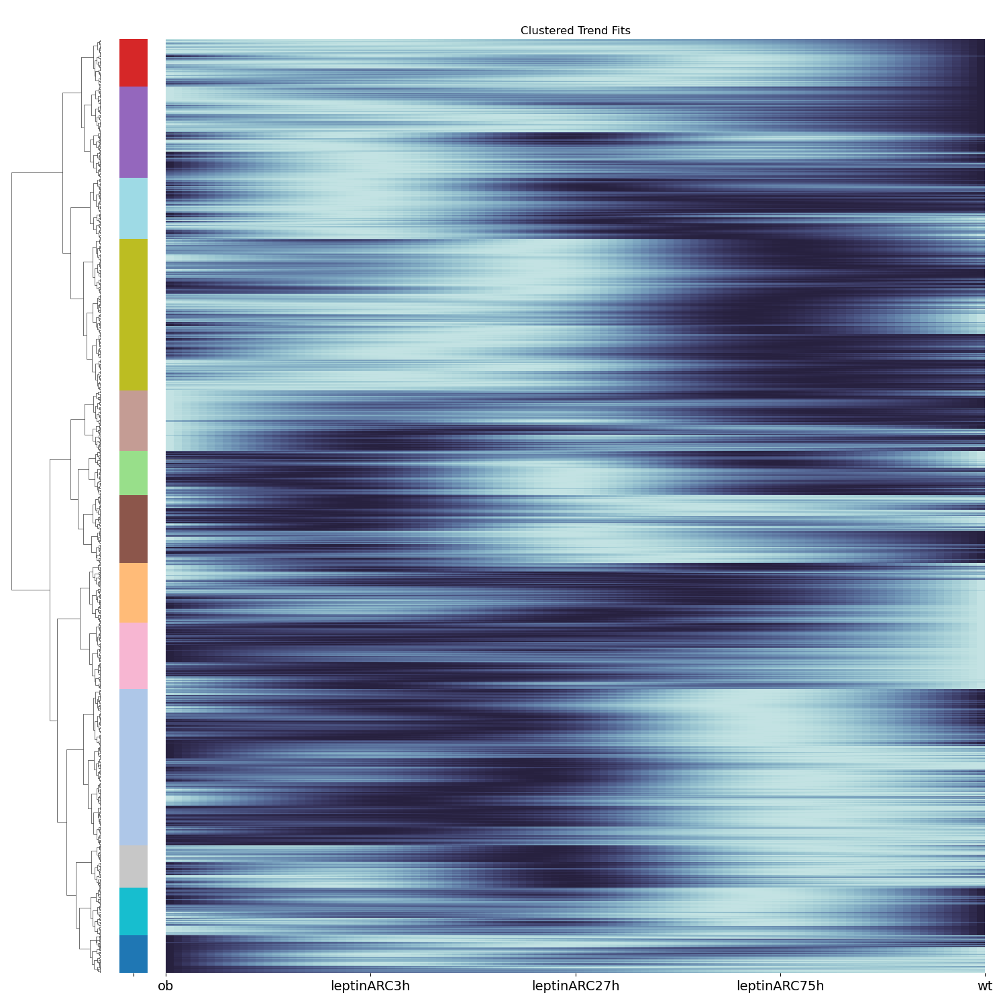

In [60]:
# Plot clustered heatmap with fixed dendrogram
ax = sns.clustermap(all_goods_df_hvg.reset_index(drop=True), 
                    row_linkage=dend_link, 
                    row_colors=row_colors, 
                    col_cluster=False, 
                     row_cluster=True, 
                     cmap=cmap, 
                     figsize=(15,15), 
                     standard_scale=0, 
                     yticklabels=[], # this needs to commented out and the reset_index needs to taken out in order to see the y axis labels
                     cbar_pos=None, 
                     dendrogram_ratio=(0.10,0.01))

num_stages = len(stage_order)
ticks = np.linspace(0, all_goods_df_hvg.shape[1], num_stages)
ax.ax_heatmap.set_xticks( ticks);
ax.ax_heatmap.set_xticklabels(stage_order, rotation=90);

ax.ax_row_dendrogram.set_visible(True)

plt.setp( ax.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)

ax.ax_heatmap.set_title( "Clustered Trend Fits");

ax.ax_heatmap.set_xticklabels(
    stage_order,
    rotation=0,          # horizontal
    ha="center",
    fontsize=14          # bigger font
)

plt.tight_layout()

ax.figure.show()

# Save figure
#ax.fig.savefig(save_figure_path + "Fig1f_ARC_trend_fit_clustering.pdf", dpi=300, bbox_inches="tight")

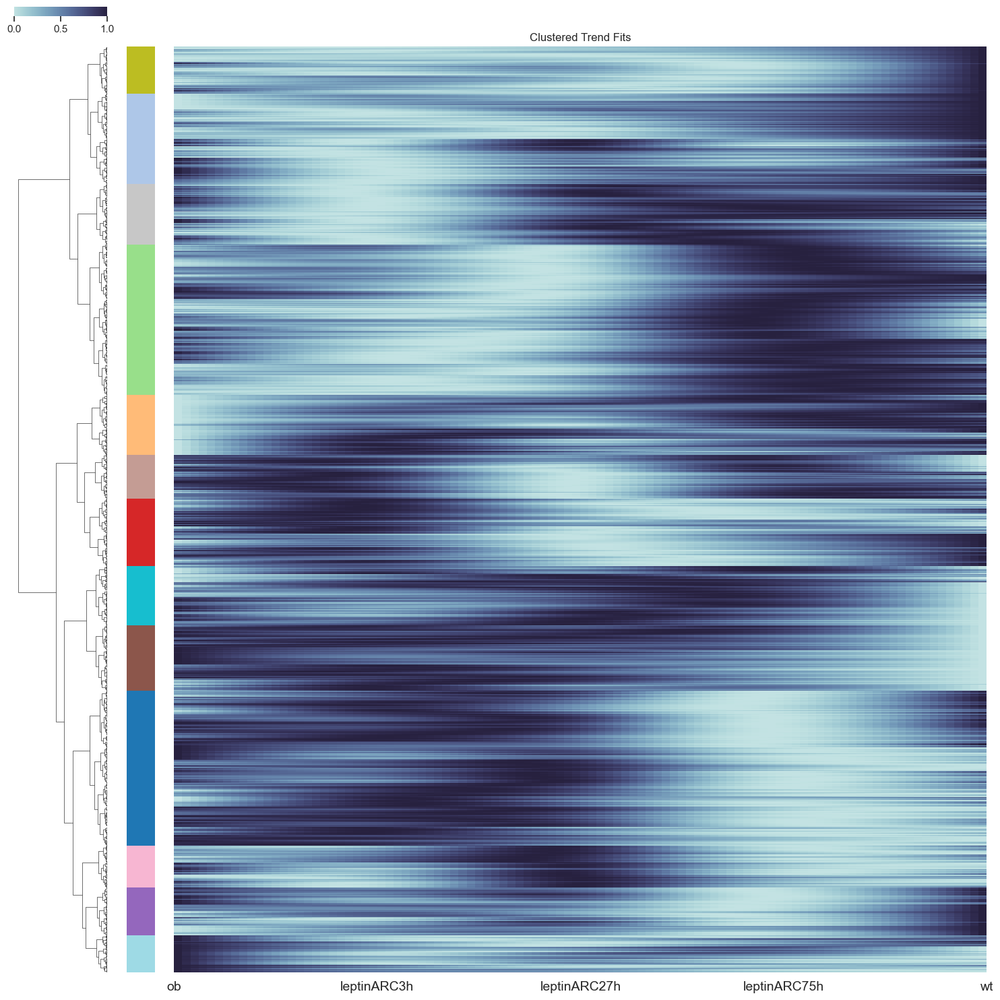

In [20]:
# to show the scale
ax = sns.clustermap(all_goods_df_hvg.reset_index(drop=True), 
                    row_linkage=dend_link, 
                    row_colors=row_colors, 
                    col_cluster=False, 
                     row_cluster=True, 
                     cmap=cmap, 
                     figsize=(15,15), 
                     standard_scale=0, 
                     yticklabels=[], # this needs to commented out and the reset_index needs to taken out in order to see the y axis labels
                     cbar_pos=(0.25, 0.92, 0.5, 0.03),   # horizontal bar on top
                     cbar_kws={"orientation": "horizontal"},
                     dendrogram_ratio=(0.10,0.01))

num_stages = len(stage_order)
ticks = np.linspace(0, all_goods_df_hvg.shape[1], num_stages)
ax.ax_heatmap.set_xticks( ticks);
ax.ax_heatmap.set_xticklabels(stage_order, rotation=90);

ax.ax_row_dendrogram.set_visible(True)

plt.setp( ax.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)

ax.ax_heatmap.set_title( "Clustered Trend Fits");

ax.ax_heatmap.set_xticklabels(
    stage_order,
    rotation=0,          # horizontal
    ha="center",
    fontsize=14          # bigger font
)

plt.subplots_adjust(top=0.9)
plt.tight_layout()

#ax.figure.show()

ax.fig.savefig(save_figure_path + "Fig1/scale/Fig1f_ARC_trend_fit_clustering.pdf", dpi=300, bbox_inches="tight")

In [61]:
go_df['module'] = cut_tree
go_df.head()

,,0,1,2,3,4,5,6,7,8,9,...,91,92,93,94,95,96,97,98,99,module
cluster,gene,,,,,,,,,,,,,,,,,,,,,
0,Pcsk2,8.805644,8.752948,8.700514,8.648440,8.596826,8.545770,8.495370,8.445727,8.396938,8.349104,...,8.218668,8.221828,8.224951,8.228041,8.231102,8.234139,8.237156,8.240158,8.243148,0
10,Pcsk2,8.031347,7.979809,7.928763,7.878395,7.828892,7.780438,7.733220,7.687423,7.643234,7.600841,...,7.198610,7.225858,7.254115,7.283264,7.313189,7.343772,7.374897,7.406448,7.438308,1
11,Pcsk2,9.151298,9.113017,9.074965,9.037228,8.999892,8.963043,8.926768,8.891152,8.856282,8.822245,...,8.499007,8.465477,8.431501,8.397130,8.362416,8.327410,8.292164,8.256730,8.221159,2
12,Pcsk2,7.622579,7.599023,7.575531,7.552126,7.528833,7.505675,7.482677,7.459861,7.437253,7.414877,...,7.040556,6.997546,6.953778,6.909341,6.864323,6.818810,6.772891,6.726652,6.680182,3
13,Pcsk2,9.089887,9.090914,9.091978,9.093092,9.094271,9.095528,9.096878,9.098334,9.099911,9.101621,...,8.925460,8.933861,8.942567,8.951541,8.960748,8.970154,8.979722,8.989419,8.999209,1


In [ ]:
plt.figure(figsize=(8, 5))

for module in module_mean_z.index:
    plt.plot(
        module_mean_z.columns,
        module_mean_z.loc[module],
        marker="o",
        label=f"Module {module}"
    )

plt.xlabel("Stage")
plt.ylabel("Z-scored expression")
plt.title("Average Expression Trajectories per Gene Module")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 1g ARC individual cluster trends

In [ ]:
# generalized trends
down       = ['7', '10', '8']
inter_down = ['9', '4', '11','6']
inter_up   = ['2']
up         = ['1','3','5']
up_down_up_down = ['12', '0']


In [15]:
def plot_tend_avg(ax, genes, trend_df, scat_df, color='green', alpha=1.0):
    min_max_scaler = preprocessing.MinMaxScaler()

    trends = trend_df.loc[genes, :]
    norm_td = min_max_scaler.fit_transform(trends.T)
    avg_td = np.mean(norm_td, axis=1)

    ax.plot(norm_td, linewidth=1.0, alpha=0.01, color=color)
    ax.plot(avg_td, linewidth=2.5, alpha=alpha, color='black')

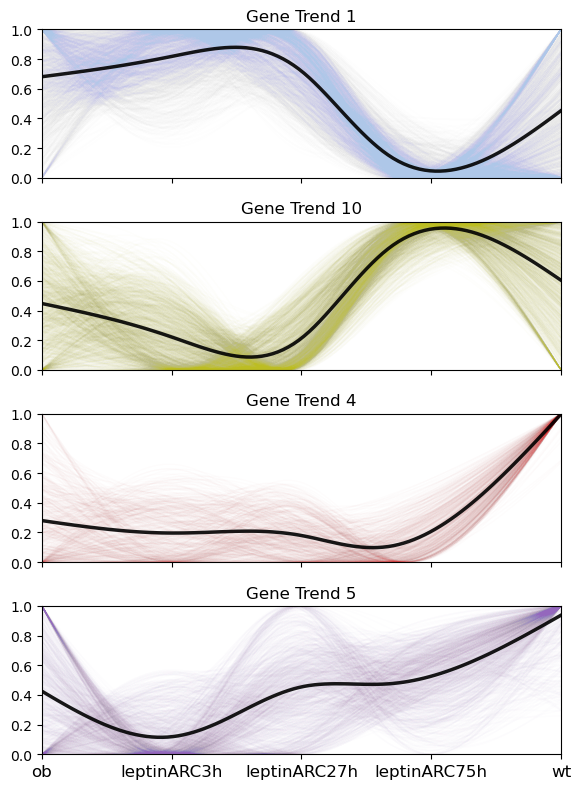

In [17]:
cluster_plot = [1, 10, 4, 5]  # representative clusters

#n_splines = 15
n_grid_pts = 100

fig, axes = plt.subplots(
    nrows=len(cluster_plot),
    ncols=1,
    figsize=(2 * 3, 2 * len(cluster_plot)),
    sharex=True
)

for i, clust_itr in enumerate(cluster_plot):
    ax = axes[i]

    clust_mk = cut_tree == clust_itr
    #print(clust_itr, sum(clust_mk))

    clust_genes = all_goods_df_hvg.index[clust_mk]

    plot_tend_avg(
        ax,
        clust_genes,
        all_goods_df_hvg,
        logTMMs['0'],
        alpha=0.9,
        color=cluster_colors[clust_itr]
    )

    ax.set_title(f"Gene Trend {clust_itr}")
    ax.set_ylim(0.0, 1.0)
    ax.set_xlim(0, n_grid_pts - 1)

    # Hide x-axis labels for all but bottom plot
    if i < len(cluster_plot) - 1:
        ax.tick_params(labelbottom=False)


ticks = np.linspace(0, n_grid_pts - 1, num_stages)

axes[-1].set_xticks(ticks)
axes[-1].set_xticklabels(stage_order, rotation=0, fontsize=12)

plt.tight_layout()
plt.show()
#plt.savefig(save_figure_path + "Fig1g_ARC_trend_fit_clustering.pdf", 
#            dpi=300, bbox_inches="tight")

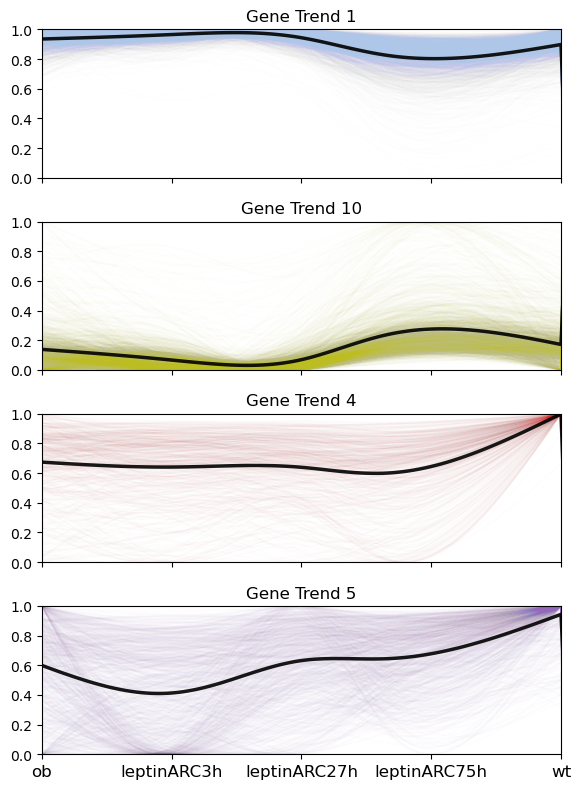

In [ ]:
cluster_plot = [1, 10, 4, 5]  # representative clusters

#n_splines = 15
n_grid_pts = 100

fig, axes = plt.subplots(
    nrows=len(cluster_plot),
    ncols=1,
    figsize=(2 * 3, 2 * len(cluster_plot)),
    sharex=True
)

for i, clust_itr in enumerate(cluster_plot):
    ax = axes[i]

    clust_mk = cut_tree == clust_itr
    #print(clust_itr, sum(clust_mk))

    clust_genes = go_df[go_df['module'] == clust_itr].index

    plot_tend_avg(
        ax,
        clust_genes,
        all_goods_df_hvg,
        logTMMs['0'],
        alpha=0.9,
        color=cluster_colors[clust_itr]
    )

    ax.set_title(f"Gene Trend {clust_itr}")
    ax.set_ylim(0.0, 1.0)
    ax.set_xlim(0, n_grid_pts - 1)

    # Hide x-axis labels for all but bottom plot
    if i < len(cluster_plot) - 1:
        ax.tick_params(labelbottom=False)


ticks = np.linspace(0, n_grid_pts - 1, num_stages)

axes[-1].set_xticks(ticks)
axes[-1].set_xticklabels(stage_order, rotation=0, fontsize=12)

plt.tight_layout()
plt.show()
#plt.savefig(save_figure_path + "Fig1g_ARC_trend_fit_clustering.pdf", 
#            dpi=300, bbox_inches="tight")


# generalized trends
down       = ['7', '10', '8']
inter_down = ['9', '4', '11','6']
inter_up   = ['2']
up         = ['1','3','5']
up_down_up_down = ['12', '0']


### 1h ARC Gene Trend Go term analysis
notebook 16

In [ ]:
mat_degs = pd.read_pickle("./snRNAseq/data/devDEG_Gene-Ontology-hits.pkl")

df = pd.DataFrame()
for i in (['1', '10', '4', '5']):
    #print(i)
    tmp = mat_degs[i]
    tmp['group'] = i
    df = pd.concat([df,tmp], axis=0)
    #print(df.shape)

df_sub = df[df['name'].isin(['peptide metabolic process', 'ion binding', 'regulation of vesicle-mediated transport', 'regulation of protein localization','heterocycle catabolic process', 'peptide biosynthetic process',
                             'nucleotide binding', 'regulation of synapse structure or activity', 'synapse assembly', 'dendritic spine development'])]
df_sub['Gene ratio'] = df_sub['term_size'].values / df_sub['query_size'].values

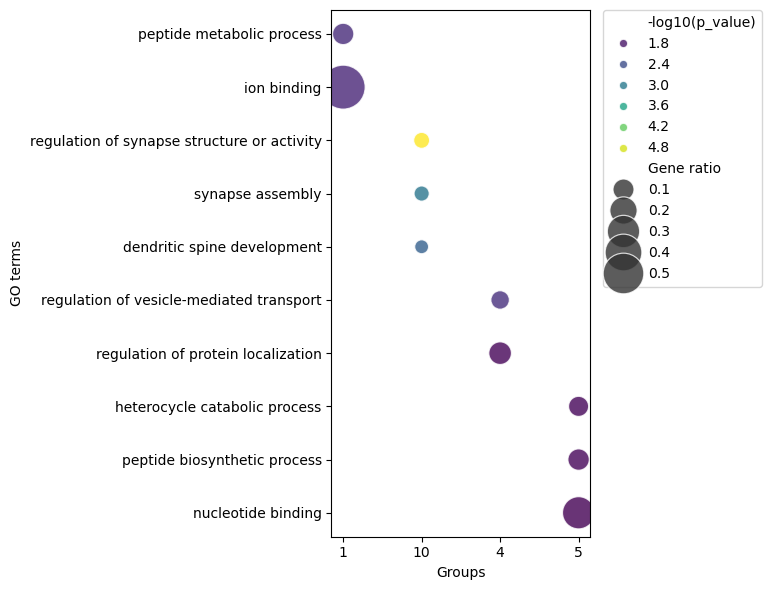

In [83]:
df_sub['-log10(p_value)'] = -np.log10(df_sub['p_value'])

plt.figure(figsize=(8, 6))  # increase width for better label spacing
ax = sns.scatterplot(
    data=df_sub,
    y="name", x="group",
    size='Gene ratio', hue='-log10(p_value)',
    sizes=(100, 1000), palette="viridis", alpha=0.8,
)

# Move legend outside
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0.)

# Rotate x-axis labels
#plt.xticks(rotation=45, ha='right')
plt.ylabel('GO terms')
plt.xlabel('Groups')

# Layout fix to prevent clipping
plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + 'Fig1h_ARC_GO_terms.pdf', dpi=400, bbox_inches='tight')

### Rethinking this go term analysis

In [ ]:
# load data for ARC
adata = sc.read( "adata_seurat_111621_scvelo.h5ad")
adata = adata[adata.obs['clusters'].isin(['0','1','2','3','4','5','6','7','8','10',
                                  '11','12','13','14','16','17','18','19','22'])]

#n_splines = 15
#n_grid_pts = 100
logTMMs = nmc.load_obj( "./snRNAseq/data/logTMMs.pkl")
gam_fits = nmc.load_obj( "./snRNAseq/data/AGE_gam_fits_15_grid100.pkl")

all_goods_df = pd.concat( list( gam_fits.values()), keys=list(gam_fits.keys()))
all_goods_df.index.names = ['cluster', 'gene']

# get highly variable genes
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
hvg_genes = adata.var_names[adata.var.highly_variable]

In [79]:
from gprofiler import GProfiler
def query_genes( genes, bk_grd, p_thresh=0.05):
    # Gprofiler does not like Y_RNA, times out
    if 'Y_RNA' in genes:
        genes.remove('Y_RNA')
    # base url sets version used in our study
    gp = GProfiler( return_dataframe=True, base_url="https://biit.cs.ut.ee/gprofiler_archive3/e102_eg49_p15/")
    query_df = gp.profile( organism='mmusculus', query=genes, user_threshold=p_thresh, background=bk_grd)
    ####################################################
    query_df = query_df[np.in1d( query_df['source'].values, ['GO:MF','GO:BP'])]
    ####################################################
    # if you'd like less general GOs
#     parent_mk = np.array( [len( ii)>=0 for ii in query_df['parents'].values])
    return( query_df) #.loc[parent_mk])

In [ ]:
sig_genes = {}

for gene_cl in all_goods_df_hvg["gene_cluster"].unique():

    genes = (
        all_goods_df_hvg
        .query("gene_cluster == @gene_cl")
        .index.get_level_values("gene")
        .unique()
        .tolist()
    )

    if len(genes) >= 5:
        sig_genes[gene_cl] = genes


below the trend was done is a cluster specific manner

In [ ]:
background_by_cell = {}

cell_clusters = all_goods_df_hvg.index.get_level_values("cluster").unique()

for cell_cl in cell_clusters:
    bg_genes = (
        all_goods_df_hvg
        .loc[(cell_cl, slice(None)), :]
        .index.get_level_values("gene")
        .unique()
        .tolist()
    )
    background_by_cell[cell_cl] = bg_genes


sig_genes = {}

gene_clusters = all_goods_df_hvg["gene_cluster"].unique()

for cell_cl in cell_clusters:
    for gene_cl in gene_clusters:

        genes = (
            all_goods_df_hvg
            .loc[(cell_cl, slice(None)), :]
            .query("gene_cluster == @gene_cl")
            .index.get_level_values("gene")
            .unique()
            .tolist()
        )

        if len(genes) >= 10:   # minimum size filter
            sig_genes[(cell_cl, gene_cl)] = genes



In [ ]:
# plotting
df = pd.DataFrame()
for i in (['1', '10', '4', '5']):
    #print(i)
    tmp = all_q_df[i]
    tmp['group'] = i
    df = pd.concat([df,tmp], axis=0)
    #print(df.shape)

df_sub = df[df['name'].isin(['peptide metabolic process', 'ion binding', 'regulation of vesicle-mediated transport', 'regulation of protein localization','heterocycle catabolic process', 'peptide biosynthetic process',
                             'nucleotide binding', 'regulation of synapse structure or activity', 'synapse assembly', 'dendritic spine development'])]
df_sub['Gene ratio'] = df_sub['term_size'].values / df_sub['query_size'].values


In [ ]:
cluster_plot = [1, 10, 4, 5]  # representative clusters

#n_splines = 15
n_grid_pts = 100

fig, axes = plt.subplots(
    nrows=len(cluster_plot),
    ncols=1,
    figsize=(2 * 3, 2 * len(cluster_plot)),
    sharex=True
)

for i, clust_itr in enumerate(cluster_plot):
    ax = axes[i]

    clust_mk = cut_tree == clust_itr
    #print(clust_itr, sum(clust_mk))

    clust_genes = go_df[go_df['module'] == clust_itr].index

    plot_tend_avg(
        ax,
        clust_genes,
        all_goods_df_hvg,
        logTMMs['0'],
        alpha=0.9,
        color=cluster_colors[clust_itr]
    )

    ax.set_title(f"Gene Trend {clust_itr}")
    ax.set_ylim(0.0, 1.0)
    ax.set_xlim(0, n_grid_pts - 1)

    # Hide x-axis labels for all but bottom plot
    if i < len(cluster_plot) - 1:
        ax.tick_params(labelbottom=False)


ticks = np.linspace(0, n_grid_pts - 1, num_stages)

axes[-1].set_xticks(ticks)
axes[-1].set_xticklabels(stage_order, rotation=0, fontsize=12)

plt.tight_layout()
plt.show()
#plt.savefig(save_figure_path + "Fig1g_ARC_trend_fit_clustering.pdf", 
#            dpi=300, bbox_inches="tight")


# generalized trends
down       = ['7', '10', '8']
inter_down = ['9', '4', '11','6']
inter_up   = ['2']
up         = ['1','3','5']
up_down_up_down = ['12', '0']


In [ ]:
df_sub['-log10(p_value)'] = -np.log10(df_sub['p_value'])

plt.figure(figsize=(8, 6))  # increase width for better label spacing
ax = sns.scatterplot(
    data=df_sub,
    y="name", x="group",
    size='Gene ratio', hue='-log10(p_value)',
    sizes=(100, 1000), palette="viridis", alpha=0.8,
)

# Move legend outside
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0.)

# Rotate x-axis labels
#plt.xticks(rotation=45, ha='right')
plt.ylabel('GO terms')
plt.xlabel('Groups')

# Layout fix to prevent clipping
plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + 'Fig1h_ARC_GO_terms.pdf', dpi=400, bbox_inches='tight')

### 1i PVH DEGs histogram

In [ ]:
# load the previous analysis results DGE results
logTMMs = nmc.load_obj( "./snRNAseq/data/limma-voom/pvh/logTMMs.pkl")
gam_fits = nmc.load_obj( "./snRNAseq/data/limma-voom/pvh/AGE_gam_fits_15_grid100.pkl")
sig_genes = {}
for traj_itr, df_itr in logTMMs.items():
    sig_genes[traj_itr] = df_itr.index.values
gene_dict = sig_genes

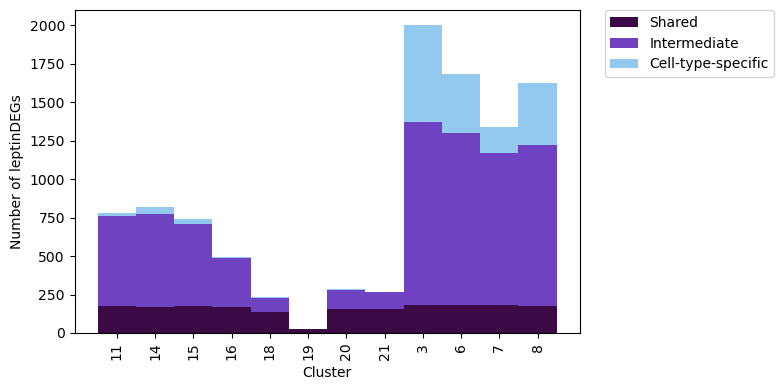

In [ ]:
# Plotting the shared vs unique DEGs across clusters
# Step 1: Count gene occurrences across cell types
gene_counts = Counter(g for genes in gene_dict.values() for g in genes)
total_celltypes = len(gene_dict)

# Step 2: Classify each gene by frequency
gene_category = {}
for gene, count in gene_counts.items():
    freq = count / total_celltypes
    if freq <= 0.2: # hard coded
        gene_category[gene] = "unique"
    elif freq >= 0.7: # hard coded
        gene_category[gene] = "shared"
    else:
        gene_category[gene] = "intermediate"

# Step 3: Count gene types per cell type
summary = defaultdict(lambda: {"unique": 0, "shared": 0, "intermediate": 0})

for celltype, genes in gene_dict.items():
    for g in genes:
        cat = gene_category.get(g)
        if cat in summary[celltype]:
            summary[celltype][cat] += 1

# Step 4: Prepare values for plotting
celltypes = list(summary.keys())
unique_vals = [summary[ct]["unique"] for ct in celltypes]
shared_20_vals = [summary[ct]["intermediate"] for ct in celltypes]
shared_70_vals = [summary[ct]["shared"] for ct in celltypes]

# Step 5: Plot stacked bar chart (absolute counts)
x = np.arange(len(celltypes))

plt.figure(figsize=(8, 4))
plt.bar(x, shared_70_vals, width=1, label="Shared", color="#3B0A45")
plt.bar(x, shared_20_vals, width=1, bottom=shared_70_vals, label="Intermediate", color="#6F42C1")
plt.bar(x, unique_vals, width=1, bottom=np.array(shared_70_vals)+np.array(shared_20_vals), label="Cell-type-specific", color="#94C9EF")
plt.xticks(x, celltypes, rotation=90)
plt.ylabel("Number of leptinDEGs")
plt.xlabel("Cluster")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + 'Fig1i_PVH_devGenes_shared.pdf', dpi=800)


In [ ]:
# adding cluster 22 back on
# load the previous analysis results DGE results
logTMMs = nmc.load_obj( "./snRNAseq/data/limma-voom/pvhv2/logTMMs.pkl")
gam_fits = nmc.load_obj( "./snRNAseq/data/limma-voom/pvhv2/AGE_gam_fits_15_grid100.pkl")
sig_genes = {}
for traj_itr, df_itr in logTMMs.items():
    sig_genes[traj_itr] = df_itr.index.values
gene_dict = sig_genes

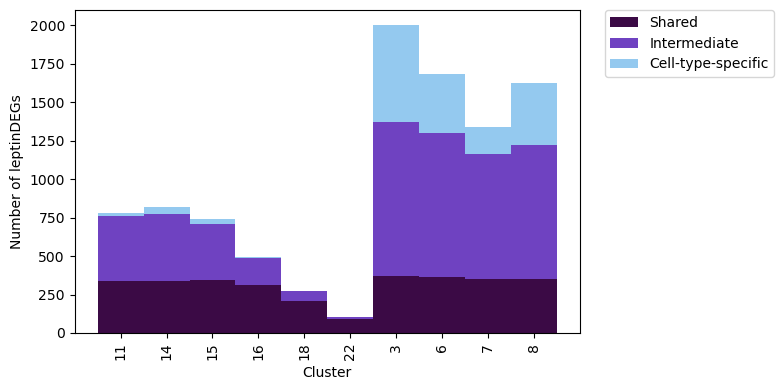

In [14]:
# Plotting the shared vs unique DEGs across clusters
# Step 1: Count gene occurrences across cell types
gene_counts = Counter(g for genes in gene_dict.values() for g in genes)
total_celltypes = len(gene_dict)

# Step 2: Classify each gene by frequency
gene_category = {}
for gene, count in gene_counts.items():
    freq = count / total_celltypes
    if freq <= 0.2: # hard coded
        gene_category[gene] = "unique"
    elif freq >= 0.7: # hard coded
        gene_category[gene] = "shared"
    else:
        gene_category[gene] = "intermediate"

# Step 3: Count gene types per cell type
summary = defaultdict(lambda: {"unique": 0, "shared": 0, "intermediate": 0})

for celltype, genes in gene_dict.items():
    for g in genes:
        cat = gene_category.get(g)
        if cat in summary[celltype]:
            summary[celltype][cat] += 1

# Step 4: Prepare values for plotting
celltypes = list(summary.keys())
unique_vals = [summary[ct]["unique"] for ct in celltypes]
shared_20_vals = [summary[ct]["intermediate"] for ct in celltypes]
shared_70_vals = [summary[ct]["shared"] for ct in celltypes]

# Step 5: Plot stacked bar chart (absolute counts)
x = np.arange(len(celltypes))

plt.figure(figsize=(8, 4))
plt.bar(x, shared_70_vals, width=1, label="Shared", color="#3B0A45")
plt.bar(x, shared_20_vals, width=1, bottom=shared_70_vals, label="Intermediate", color="#6F42C1")
plt.bar(x, unique_vals, width=1, bottom=np.array(shared_70_vals)+np.array(shared_20_vals), label="Cell-type-specific", color="#94C9EF")
plt.xticks(x, celltypes, rotation=90)
plt.ylabel("Number of leptinDEGs")
plt.xlabel("Cluster")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + 'Fig1/Fig1i_PVH_devGenes_shared_w_clust22.pdf', dpi=800)


### 1j PVH Gene trend heatmap

In [ ]:
# load data for ARC
adata = sc.read( "adata_seurat_PVH_111621_v2_scvelo.h5ad")
adata = adata[adata.obs['clusters'].isin([3,6,7,8,11,14,15,16,18,22])]

n_splines = 15
n_grid_pts = 100
logTMMs = nmc.load_obj( "./snRNAseq/data/limma-voom/pvh/logTMMs.pkl")
gam_fits = nmc.load_obj( "./snRNAseq/data/limma-voom/pvh/AGE_gam_fits_15_grid100.pkl")

all_goods_df = pd.concat( list( gam_fits.values()), keys=list(gam_fits.keys()))
all_goods_df.index.names = ['cluster', 'gene']

# get highly variable genes
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
hvg_genes = adata.var_names[adata.var.highly_variable]

# filter all_goods_df to only include highly variable genes
second_level_index = all_goods_df.index.get_level_values('gene')
intersection = list(set(second_level_index).intersection(hvg_genes))
all_goods_df_hvg = all_goods_df.loc[(slice(None), intersection), :]

In [5]:
all_goods_df.head()

0         1         2         3         4         5   \
cluster gene                                                                  
11      Lactb2   8.414600  8.387178  8.359589  8.331771  8.303661  8.275196   
        Actr1b   9.145845  9.156001  9.165931  9.175547  9.184764  9.193496   
        Gm33533  8.461885  8.478180  8.494274  8.510089  8.525550  8.540580   
        Rev1     8.337243  8.409867  8.481868  8.553012  8.623063  8.691788   
        Gls      9.675195  9.697577  9.719727  9.741561  9.762989  9.783925   

                       6         7         8         9   ...        90  \
cluster gene                                             ...             
11      Lactb2   8.246312  8.216948  8.187040  8.156524  ...  8.885224   
        Actr1b   9.201658  9.209164  9.215927  9.221862  ...  9.286896   
        Gm33533  8.555102  8.569042  8.582321  8.594864  ...  8.043702   
        Rev1     8.758950  8.824316  8.887649  8.948713  ...  8.449684   
        Gls      9.804283  9.823974  9.842913  9.861010  ...  8.832529   

                       91        92        93        94        95        96  \
cluster gene                                                                  
11      Lactb2   8.854004  8.821026  8.786476  8.750535  8.713384  8.675207   
        Actr1b   9.247204  9.206321  9.164374  9.121484  9.077775  9.033370   
        Gm33533  7.988492  7.932232  7.875032  7.817000  7.758246  7.698877   
        Rev1     8.462113  8.474514  8.486892  8.499249  8.511587  8.523909   
        Gls      8.830136  8.827890  8.825775  8.823776  8.821878  8.820066   

                       97        98        99  
cluster gene                                   
11      Lactb2   8.636183  8.596496  8.556328  
        Actr1b   8.988393  8.942966  8.897212  
        Gm33533  7.639003  7.578732  7.518173  
        Rev1     8.536218  8.548517  8.560809  
        Gls      8.818324  8.816638  8.814993  

[5 rows x 100 columns]

In [120]:
all_goods_df_hvg.reset_index(drop=True).shape

(2389, 100)

In [117]:
all_goods_df.index.get_level_values(0).unique()

Index(['11', '14', '15', '16', '18', '19', '20', '21', '3', '6', '7', '8'], dtype='object', name='cluster')

In [121]:
all_goods_df.shape

(10291, 100)

In [ ]:
# cluster the gene trends to get row colors
temp_ax = sns.clustermap(
    all_goods_df_hvg,
    metric='euclidean',
    method='ward',
    col_cluster=False,
    row_cluster=True,
    cmap=cmap,
    figsize=(15, 15),
    standard_scale=0,
    #row_colors=row_colors
)

# Get linkage matrix
dend_link = temp_ax.dendrogram_row.linkage
plt.close(temp_ax.fig)


# Cut dendrogram
cut_tree = hierarchy.cut_tree(dend_link, height=50).squeeze()

# FIXED ordering of clusters
unique_clusters = np.sort(np.unique(cut_tree))

# Fixed palette
palette = cm.get_cmap("Set3", len(unique_clusters))

# Deterministic mapping
cluster_colors = {
    cl: mp.colors.rgb2hex(palette(i))
    for i, cl in enumerate(unique_clusters)
}

# Row colors (force object dtype)
row_colors = pd.Series(
    [cluster_colors[int(c)] for c in cut_tree],
    dtype="object"
)

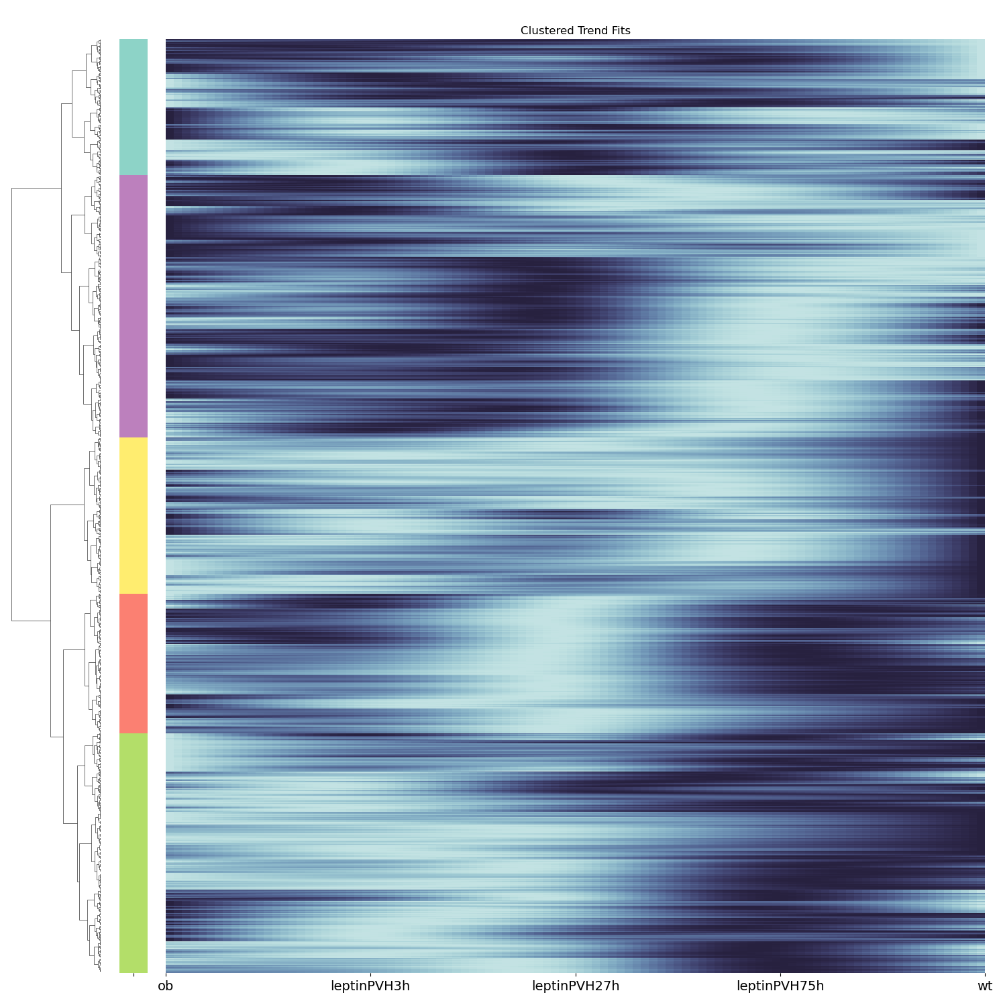

In [106]:
# Plot clustered heatmap with fixed dendrogram
ax = sns.clustermap(all_goods_df_hvg.reset_index(drop=True), 
                    row_linkage=dend_link, 
                    row_colors=row_colors, 
                    col_cluster=False, 
                     row_cluster=True, 
                     cmap=cmap, 
                     figsize=(15,15), 
                     standard_scale=0, 
                     yticklabels=[], 
                     cbar_pos=None, 
                     dendrogram_ratio=(0.10,0.01))

num_stages = len(stage_order_PVH)
ticks = np.linspace(0, all_goods_df_hvg.shape[1], num_stages)
ax.ax_heatmap.set_xticks( ticks);
ax.ax_heatmap.set_xticklabels(stage_order_PVH, rotation=90);
ax.ax_row_dendrogram.set_visible(True)

plt.setp( ax.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)

ax.ax_heatmap.set_title( "Clustered Trend Fits");

ax.ax_heatmap.set_xticklabels(
    stage_order_PVH,
    rotation=0,          # horizontal
    ha="center",
    fontsize=14          # bigger font
)

plt.tight_layout()

#ax.figure.show()

# Save figure
ax.fig.savefig(save_figure_path + "Fig1j_PVH_trend_fit_clustering.pdf",
               dpi=300, bbox_inches="tight")

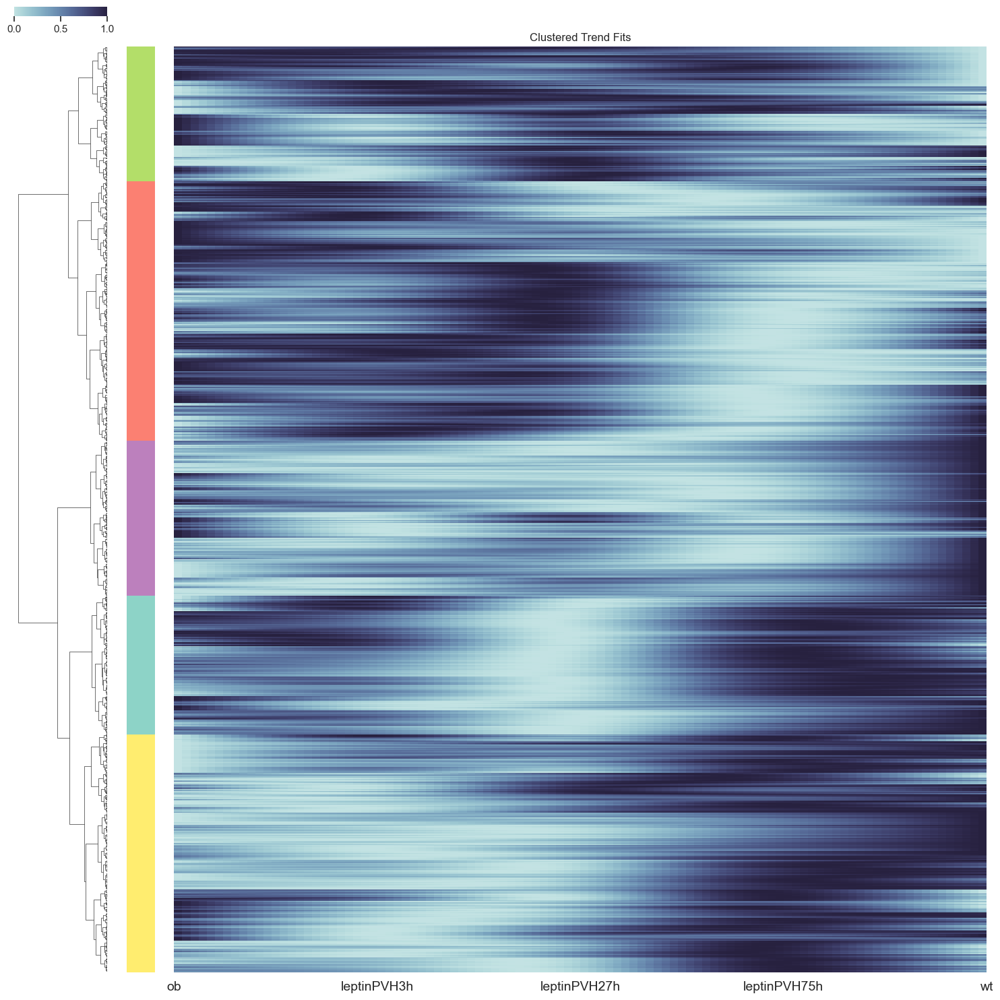

In [ ]:
# for scale
import matplotlib as mp

# load data for ARC
adata = sc.read( "adata_seurat_PVH_111621_v2_scvelo.h5ad")
adata = adata[adata.obs['clusters'].isin([3,6,7,8,11,14,15,16,18,19,20,21])]

n_splines = 15
n_grid_pts = 100
logTMMs = nmc.load_obj( "./snRNAseq/data/limma-voom/pvh/logTMMs.pkl")
gam_fits = nmc.load_obj( "./snRNAseq/data/limma-voom/pvh/AGE_gam_fits_15_grid100.pkl")

all_goods_df = pd.concat( list( gam_fits.values()), keys=list(gam_fits.keys()))
all_goods_df.index.names = ['cluster', 'gene']

# get highly variable genes
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
hvg_genes = adata.var_names[adata.var.highly_variable]

# filter all_goods_df to only include highly variable genes
second_level_index = all_goods_df.index.get_level_values('gene')
intersection = list(set(second_level_index).intersection(hvg_genes))
all_goods_df_hvg = all_goods_df.loc[(slice(None), intersection), :]

# cluster the gene trends to get row colors
temp_ax = sns.clustermap(
    all_goods_df_hvg,
    metric='euclidean',
    method='ward',
    col_cluster=False,
    row_cluster=True,
    cmap=cmap,
    figsize=(15, 15),
    standard_scale=0,
    #row_colors=row_colors
)

# Get linkage matrix
dend_link = temp_ax.dendrogram_row.linkage
plt.close(temp_ax.fig)


# Cut dendrogram
cut_tree = hierarchy.cut_tree(dend_link, height=50).squeeze()

# FIXED ordering of clusters
unique_clusters = np.sort(np.unique(cut_tree))

# Fixed palette
palette = cm.get_cmap("Set3", len(unique_clusters))

# Deterministic mapping
cluster_colors = {
    cl: mp.colors.rgb2hex(palette(i))
    for i, cl in enumerate(unique_clusters)
}

# Row colors (force object dtype)
row_colors = pd.Series(
    [cluster_colors[int(c)] for c in cut_tree],
    dtype="object"
)


# Plot clustered heatmap with fixed dendrogram
ax = sns.clustermap(all_goods_df_hvg.reset_index(drop=True), 
                    row_linkage=dend_link, 
                    row_colors=row_colors, 
                    col_cluster=False, 
                     row_cluster=True, 
                     cmap=cmap, 
                     figsize=(15,15), 
                     standard_scale=0, 
                     yticklabels=[], 
                     cbar_pos=(0.25, 0.92, 0.5, 0.03),
                     cbar_kws={"orientation": "horizontal"},
                     dendrogram_ratio=(0.10,0.01))

num_stages = len(stage_order_PVH)
ticks = np.linspace(0, all_goods_df_hvg.shape[1], num_stages)
ax.ax_heatmap.set_xticks( ticks);
ax.ax_heatmap.set_xticklabels(stage_order_PVH, rotation=90);
ax.ax_row_dendrogram.set_visible(True)

plt.setp( ax.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)

ax.ax_heatmap.set_title( "Clustered Trend Fits");

ax.ax_heatmap.set_xticklabels(
    stage_order_PVH,
    rotation=0,          # horizontal
    ha="center",
    fontsize=14          # bigger font
)
plt.subplots_adjust(top=0.9)
plt.tight_layout()

#ax.figure.show()

# Save figure
ax.fig.savefig(save_figure_path + "Fig1/scale/Fig1j_PVH_trend_fit_clusterin_scale.pdf",
               dpi=300, bbox_inches="tight")

In [ ]:
#gene_trend_color
{np.int64(0): '#8dd3c7',
 np.int64(1): '#fb8072',
 np.int64(2): '#b3de69',
 np.int64(3): '#bc80bd',
 np.int64(4): '#ffed6f'}

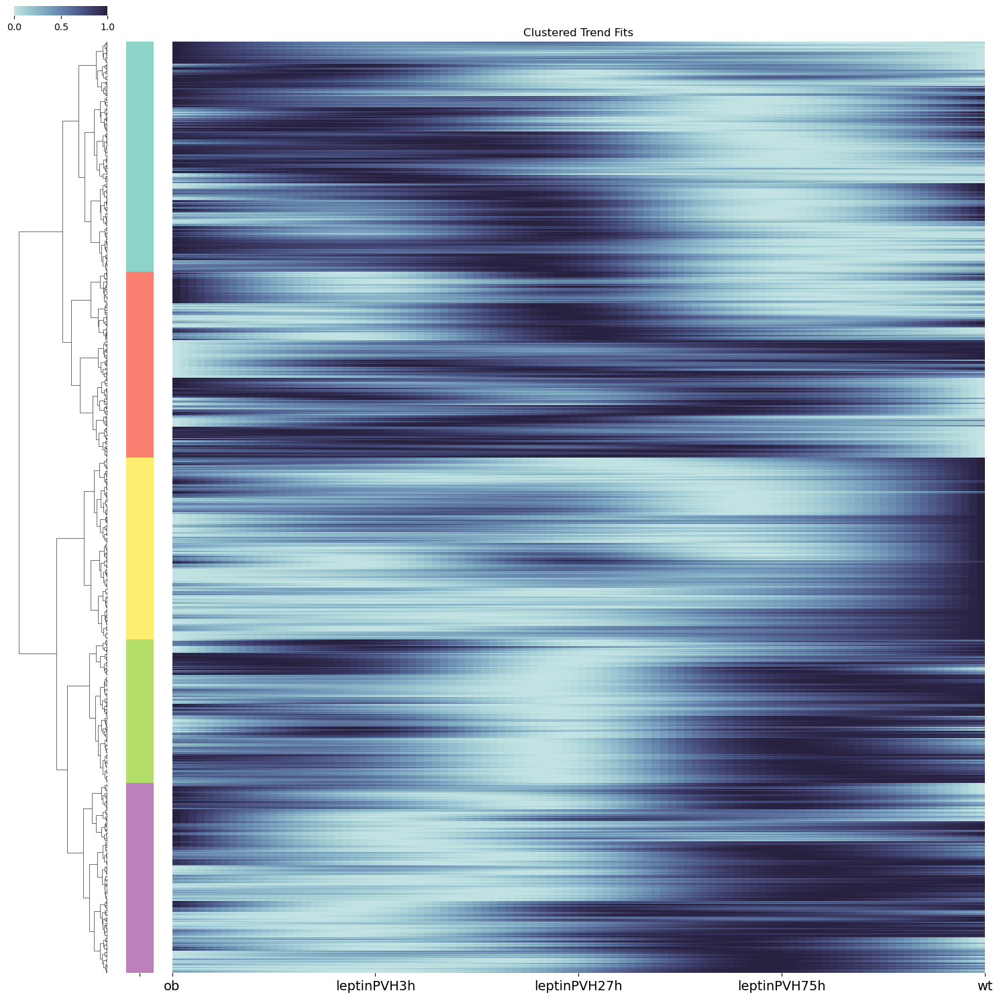

In [ ]:
# include cluster 22
import matplotlib as mp

# load data for ARC
adata = sc.read("adata_seurat_PVH_111621_v2_scvelo.h5ad")
adata = adata[adata.obs['clusters'].isin([3,6,7,8,11,14,15,16,18,22])]

n_splines = 15
n_grid_pts = 100
logTMMs = nmc.load_obj( "./snRNAseq/data/limma-voom/pvhv2/logTMMs.pkl")
gam_fits = nmc.load_obj( "./snRNAseq/data/limma-voom/pvhv2/AGE_gam_fits_15_grid100.pkl")

all_goods_df = pd.concat( list( gam_fits.values()), keys=list(gam_fits.keys()))
all_goods_df.index.names = ['cluster', 'gene']

# get highly variable genes
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
hvg_genes = adata.var_names[adata.var.highly_variable]

# filter all_goods_df to only include highly variable genes
second_level_index = all_goods_df.index.get_level_values('gene')
intersection = list(set(second_level_index).intersection(hvg_genes))
all_goods_df_hvg = all_goods_df.loc[(slice(None), intersection), :]

# cluster the gene trends to get row colors
temp_ax = sns.clustermap(
    all_goods_df_hvg,
    metric='euclidean',
    method='ward',
    col_cluster=False,
    row_cluster=True,
    cmap=cmap,
    figsize=(15, 15),
    standard_scale=0,
    #row_colors=row_colors
)

# Get linkage matrix
dend_link = temp_ax.dendrogram_row.linkage
plt.close(temp_ax.fig)


# Cut dendrogram
cut_tree = hierarchy.cut_tree(dend_link, height=50).squeeze()

# FIXED ordering of clusters
unique_clusters = np.sort(np.unique(cut_tree))

# Fixed palette
palette = cm.get_cmap("Set3", len(unique_clusters))

# Deterministic mapping
cluster_colors = {
    cl: mp.colors.rgb2hex(palette(i))
    for i, cl in enumerate(unique_clusters)
}

# Row colors (force object dtype)
row_colors = pd.Series(
    [cluster_colors[int(c)] for c in cut_tree],
    dtype="object"
)


# Plot clustered heatmap with fixed dendrogram
ax = sns.clustermap(all_goods_df_hvg.reset_index(drop=True), 
                    row_linkage=dend_link, 
                    row_colors=row_colors, 
                    col_cluster=False, 
                     row_cluster=True, 
                     cmap=cmap, 
                     figsize=(15,15), 
                     standard_scale=0, 
                     yticklabels=[], 
                     cbar_pos=(0.25, 0.92, 0.5, 0.03),
                     cbar_kws={"orientation": "horizontal"},
                     dendrogram_ratio=(0.10,0.01))

num_stages = len(stage_order_PVH)
ticks = np.linspace(0, all_goods_df_hvg.shape[1], num_stages)
ax.ax_heatmap.set_xticks( ticks);
ax.ax_heatmap.set_xticklabels(stage_order_PVH, rotation=90);
ax.ax_row_dendrogram.set_visible(True)

plt.setp( ax.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)

ax.ax_heatmap.set_title( "Clustered Trend Fits");

ax.ax_heatmap.set_xticklabels(
    stage_order_PVH,
    rotation=0,          # horizontal
    ha="center",
    fontsize=14          # bigger font
)
plt.subplots_adjust(top=0.9)
plt.tight_layout()

#ax.figure.show()

# Save figure
ax.fig.savefig(save_figure_path + "Fig1/Fig1j_PVH_trend_fit_clusterin_scale_wclus22.pdf",
               dpi=300, bbox_inches="tight")

### 1k PVH individual cluster trends


In [ ]:
# generalized trends
down       = [3]
inter_down = [1]
up         = [2]
inter_up   = [0, 4]


In [98]:
def plot_tend_avg(ax, genes, trend_df, scat_df, color='green', alpha=1.0):
    min_max_scaler = preprocessing.MinMaxScaler()

    trends = trend_df.loc[genes, :]
    norm_td = min_max_scaler.fit_transform(trends.T)
    avg_td = np.mean(norm_td, axis=1)

    ax.plot(norm_td, linewidth=1.0, alpha=0.01, color=color)
    ax.plot(avg_td, linewidth=2.5, alpha=alpha, color='black')


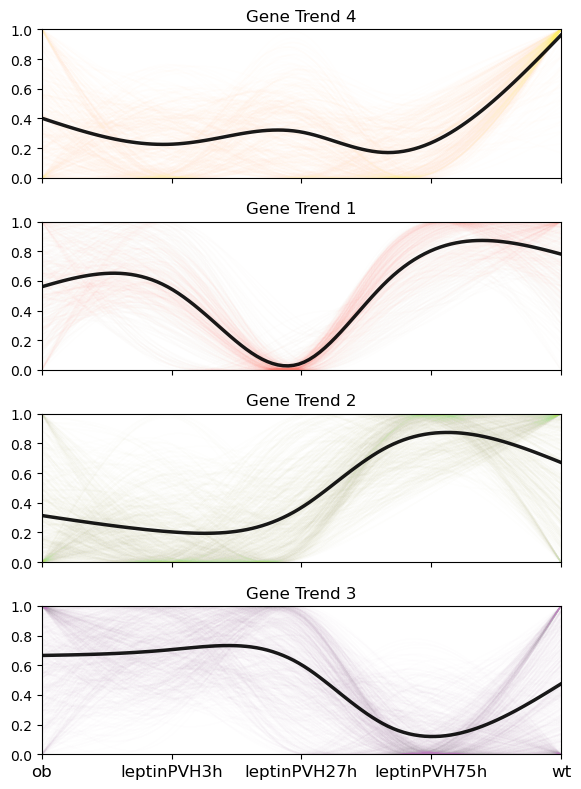

In [107]:
cluster_plot = [4, 1, 2, 3]  # representative clusters

fig, axes = plt.subplots(
    nrows=len(cluster_plot),
    ncols=1,
    figsize=(2 * 3, 2 * len(cluster_plot)),
    sharex=True
)

for i, clust_itr in enumerate(cluster_plot):
    ax = axes[i]

    clust_mk = cut_tree == clust_itr
    #print(clust_itr, sum(clust_mk))

    clust_genes = all_goods_df_hvg.index[clust_mk]

    plot_tend_avg(
        ax,
        clust_genes,
        all_goods_df_hvg,
        logTMMs['3'],
        alpha=0.9,
        color=cluster_colors[clust_itr]
    )

    ax.set_title(f"Gene Trend {clust_itr}")
    ax.set_ylim(0.0, 1.0)
    ax.set_xlim(0, n_grid_pts - 1)

    # Hide x-axis labels for all but bottom plot
    if i < len(cluster_plot) - 1:
        ax.tick_params(labelbottom=False)


ticks = np.linspace(0, n_grid_pts - 1, num_stages)

axes[-1].set_xticks(ticks)
axes[-1].set_xticklabels(stage_order_PVH, rotation=0, fontsize=12)

plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + "Fig1j_PVH_trend_fit_clustering.pdf", 
            dpi=300, bbox_inches="tight")

### 1I PVH Gene Trend Go term analysis

In [ ]:
df = pd.DataFrame()
for i in (['4', '1', '2', '3']):
    #print(i)
    tmp = mat_degs[i]
    tmp['group'] = i
    df = pd.concat([df,tmp], axis=0)
    #print(df.shape)

In [ ]:
df_sub = df[df['name'].isin(['peptide metabolic process', 'ion binding', 'regulation of vesicle-mediated transport', 'regulation of protein localization','heterocycle catabolic process', 'peptide biosynthetic process',
                             'nucleotide binding', 'regulation of synapse structure or activity', 'synapse assembly', 'dendritic spine development'])]
df_sub['Gene ratio'] = df_sub['term_size'].values / df_sub['query_size'].values

stage_order = ['ob', 'leptinPVH3h', 'leptinPVH24h', 'leptinPVH72h', 'wt']
stage = ['ob', 'leptinPVH3h', 'leptinPVH24h', 'leptinPVH72h', 'wt']
stage_num = np.array([0,3/24, 27/24, 75/24, 12*7])
age_dict = dict(zip(stage, stage_num))
n_splines = 15
n_grid_pts = 100

# Figure 2

In [ ]:
# scNeuron environment
import scanpy as sc
import pandas as pd
import numpy as np
import scvelo as scv
import seaborn as sns
import matplotlib.pyplot as plt
from scvelo.utils import vcorrcoef
scv.set_figure_params()

save_figure_path = './Leptin_manuscript/individual_fig/'
python_data_path = './snRNA-seq (1)/Procesed_data/python/'

### 2a

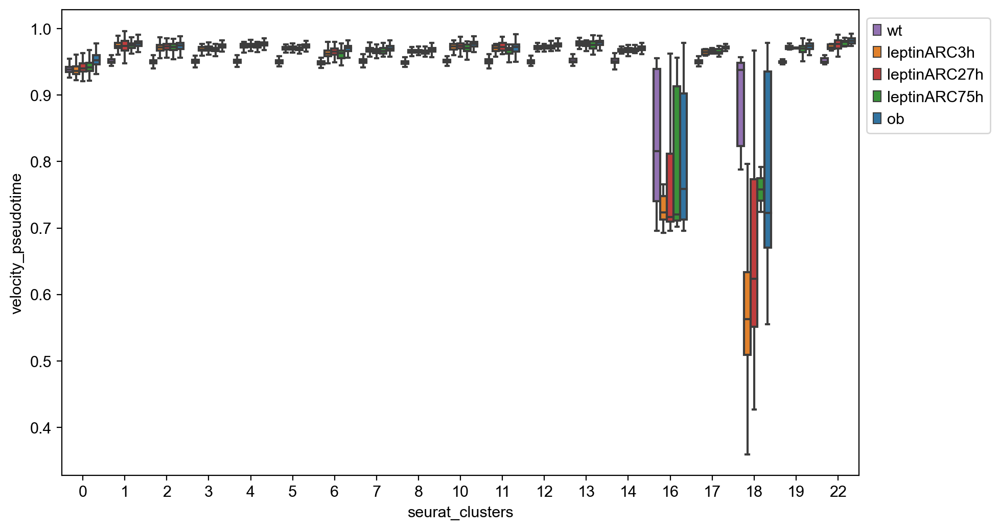

In [ ]:
metadata_df = pd.read_csv(python_data_path + 'metadata_arc_pt.csv', index_col=0)
metadata_df.head()

#this is velocity pseudotime of all neuronal clusters
metadata_df_sub = metadata_df[~metadata_df.seurat_clusters.isin([9, 15, 20, 21, 23, 24])]

# map condition to the new condition names
metadata_df_sub["condition"] = metadata_df_sub["condition"].map({
    "ob": "ob",
    "leptinARC3h": "leptinARC3h",
    "leptinARC24h": "leptinARC27h",
    "leptinARC72h": "leptinARC75h",
    "wt": "wt"
})

plt.figure(figsize=(10, 6))
ax = sns.boxplot(x="seurat_clusters", y="velocity_pseudotime", hue="condition", 
                 hue_order=["wt", "leptinARC3h", "leptinARC27h", "leptinARC75h", "ob",], # need to update the hue order to match the actual conditions in your data
                 palette={'leptinARC27h': '#d62728', 'leptinARC3h': '#ff7f0e', 'ob': '#1f77b4', 'leptinARC75h': '#2ca02c', 'wt': '#9467bd'},
                 showfliers = False,
                data=metadata_df_sub)
plt.legend(bbox_to_anchor=(1.0, 1.0))
#plt.show()
plt.savefig(save_figure_path + 'Fig2/'+'Fig2a_arc_cluster_scvelo_pt_barplot_swarmplot_060325.pdf', bbox_inches='tight')    

### 2b

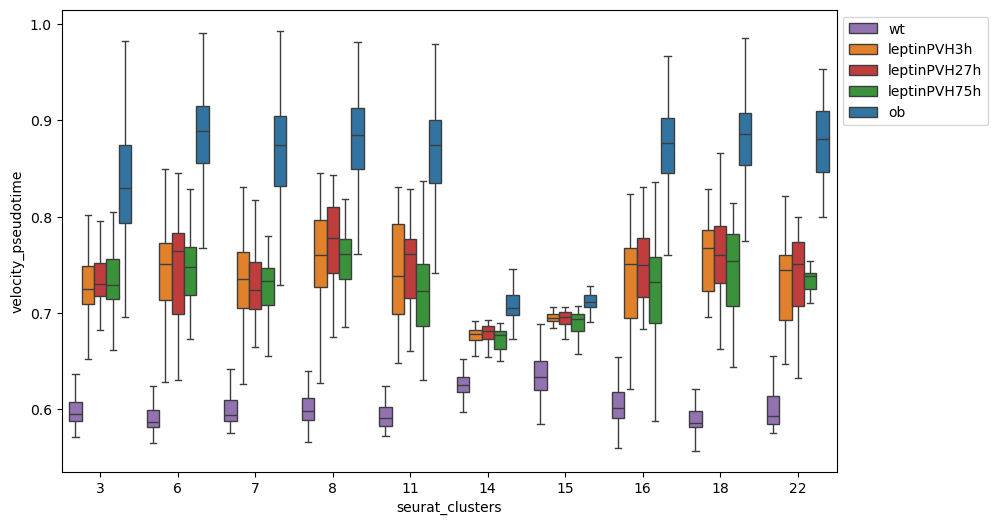

In [ ]:
metadata_df = pd.read_csv(python_data_path + 'metadata_pvh_pt.csv', index_col=0)

metadata_df_sub = metadata_df[metadata_df.seurat_clusters.isin([3,6,7,8,11,14,15,16,18,22])]

# map condition to the new condition names
metadata_df_sub["condition"] = metadata_df_sub["condition"].map({
    "ob": "ob",
    "leptinPVH3h": "leptinPVH3h",
    "leptinPVH24h": "leptinPVH27h",
    "leptinPVH72h": "leptinPVH75h",
    "wt": "wt"
})

plt.figure(figsize=(10, 6))
ax = sns.boxplot(x="seurat_clusters", y="velocity_pseudotime", hue="condition", 
                hue_order=["wt", "leptinPVH3h", "leptinPVH27h", "leptinPVH75h", "ob"],
                palette={'leptinPVH27h': '#d62728', 'leptinPVH3h': '#ff7f0e', 'ob': '#1f77b4', 'leptinPVH75h': '#2ca02c', 'wt': '#9467bd'},
                data=metadata_df_sub, showfliers=False)
plt.legend(bbox_to_anchor=(1.0, 1.0))
#plt.show()
plt.savefig(save_figure_path + 'Fig2/'+'Fig2b_pvh_cluster_scvelo_pt_barplot_swarmplot_060325.pdf', bbox_inches='tight')    

### 2c

In [36]:
# update the condition labels to match the stage order
adata_arc = sc.read(python_data_path+"adata_seurat_111621_scvelo.h5ad")
stage_order = ['ob', 'leptinARC3h', 'leptinARC27h', 'leptinARC75h', 'wt']
stage_color_dict = dict(ob="#e04516", leptinARC3h="#8dc9d0", leptinARC27h="#23c6ea", leptinARC75h="#2127d9", wt="#22d062")
stage_dict = {'ob': 'ob', 'leptinARC3h': 'leptinARC3h', 'leptinARC24h': 'leptinARC27h', 'leptinARC72h': 'leptinARC75h', 'wt': 'wt'}
adata_arc.obs['condition'] = adata_arc.obs['condition'].map(stage_dict)
# make the condition to plot a categorical variable with the correct order
adata_arc.obs['condition'] = pd.Categorical(adata_arc.obs['condition'], categories=stage_order, ordered=True)


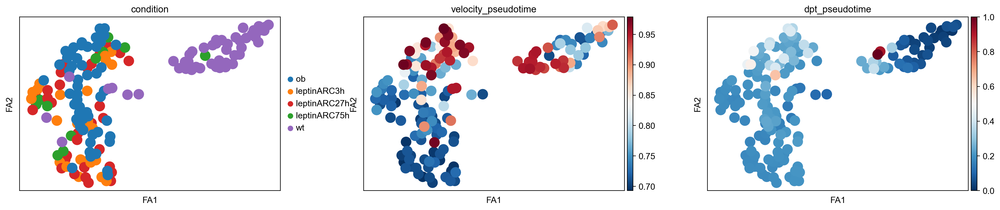

In [47]:
cluster = '16'
adata_arc_cluster = adata_arc[adata_arc.obs.clusters == cluster]
sc.tl.diffmap(adata_arc_cluster)
sc.pp.neighbors(adata_arc_cluster, n_neighbors=10, use_rep='X_diffmap')
adata_arc_cluster.uns['iroot'] = np.flatnonzero(adata_arc_cluster.obs['condition']  == 'wt')[0]
sc.tl.dpt(adata_arc_cluster)
sc.tl.draw_graph(adata_arc_cluster)
sc.pl.draw_graph(adata_arc_cluster, color=['condition', 'velocity_pseudotime','dpt_pseudotime'], wspace=0.2,palette={'leptinARC27h': '#d62728', 'leptinARC3h': '#ff7f0e', 'ob': '#1f77b4', 'leptinARC75h': '#2ca02c', 'wt': '#9467bd'})

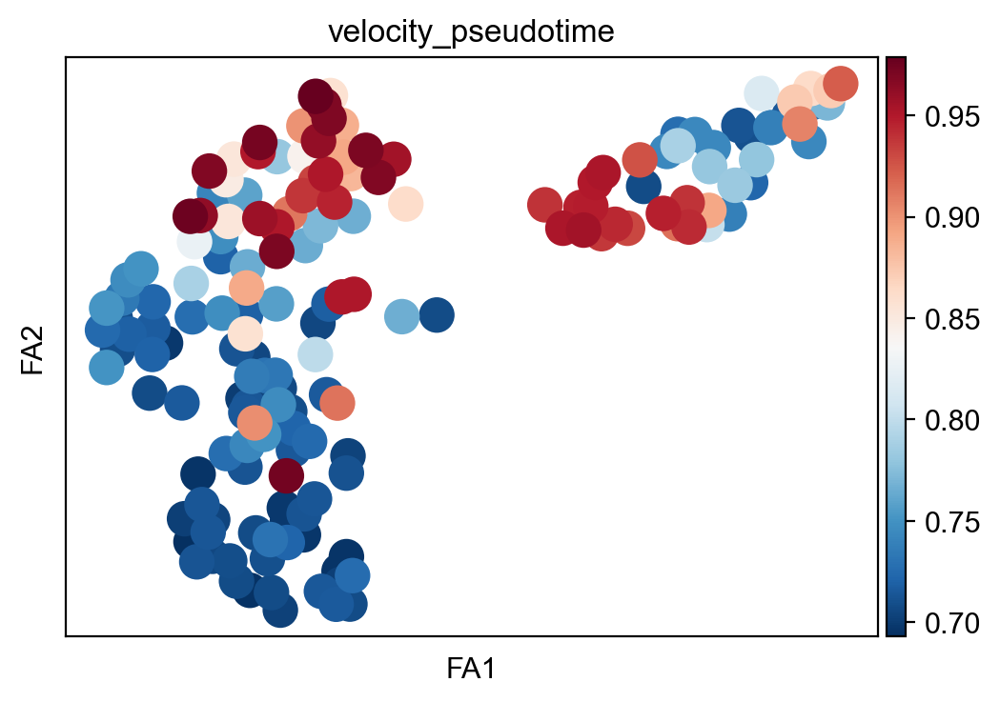

In [8]:
sc.pl.draw_graph(adata_arc_cluster, color=['velocity_pseudotime'], save= 'Fig2c_arc_cluster'+ cluster + '_scvelo_pt.pdf')

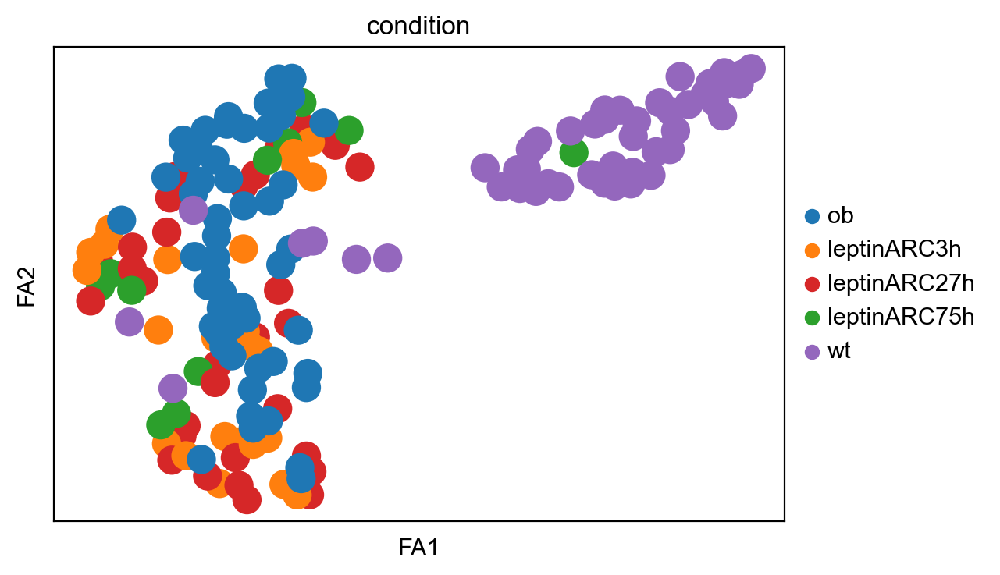

In [48]:
sc.pl.draw_graph(adata_arc_cluster, color=['condition'], 
                 palette={'leptinARC27h': '#d62728', 'leptinARC3h': '#ff7f0e', 'ob': '#1f77b4', 'leptinARC75h': '#2ca02c', 'wt': '#9467bd'},
                 save= 'Fig2c_arc_cluster'+ cluster + '_scvelo_pt_condition.pdf')

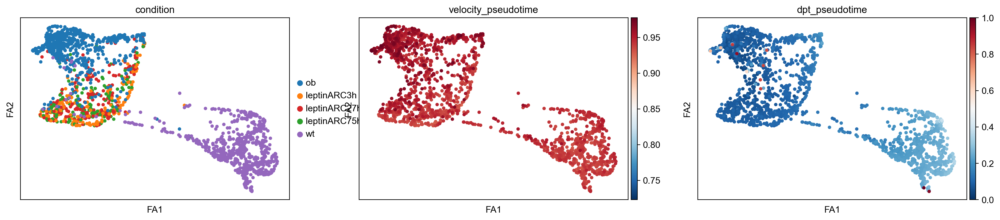

In [49]:
cluster = '0'
adata_arc_cluster = adata_arc[adata_arc.obs.clusters == cluster]
sc.tl.diffmap(adata_arc_cluster)
sc.pp.neighbors(adata_arc_cluster, n_neighbors=10, use_rep='X_diffmap')
adata_arc_cluster.uns['iroot'] = np.flatnonzero(adata_arc_cluster.obs['condition']  == 'ob')[0]
sc.tl.dpt(adata_arc_cluster)
sc.tl.draw_graph(adata_arc_cluster)
sc.pl.draw_graph(adata_arc_cluster, color=['condition','velocity_pseudotime', 'dpt_pseudotime'],
                 palette={'leptinARC27h': '#d62728', 'leptinARC3h': '#ff7f0e', 'ob': '#1f77b4', 'leptinARC75h': '#2ca02c', 'wt': '#9467bd'},)

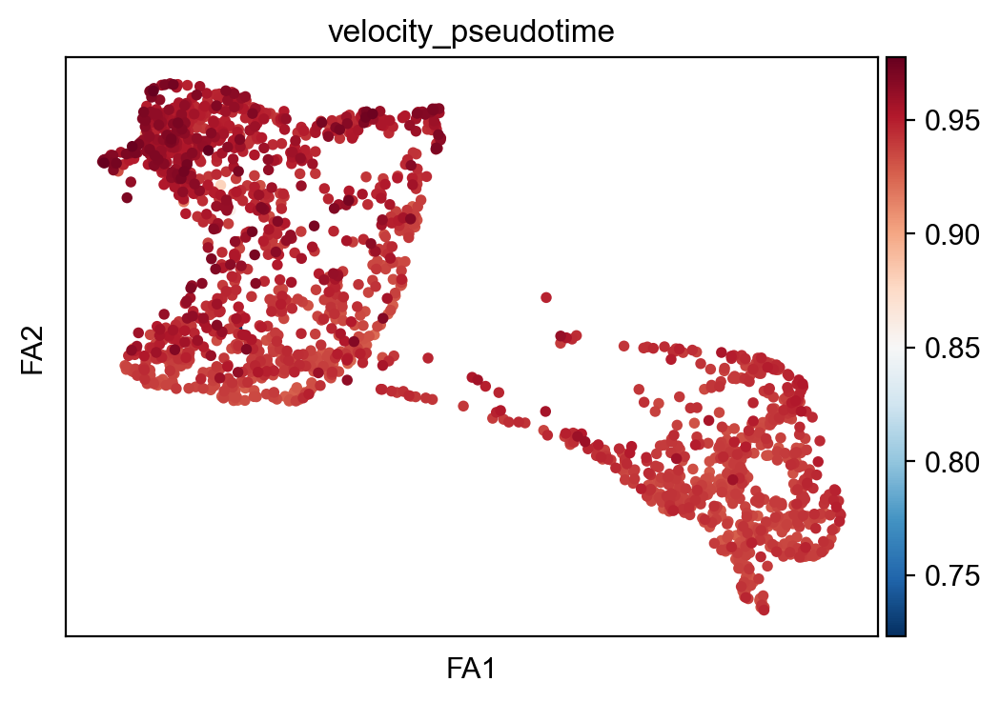

In [11]:
sc.pl.draw_graph(adata_arc_cluster, color=['velocity_pseudotime'], save= 'Fig2c_arc_cluster'+ cluster + '_scvelo_pt.pdf')

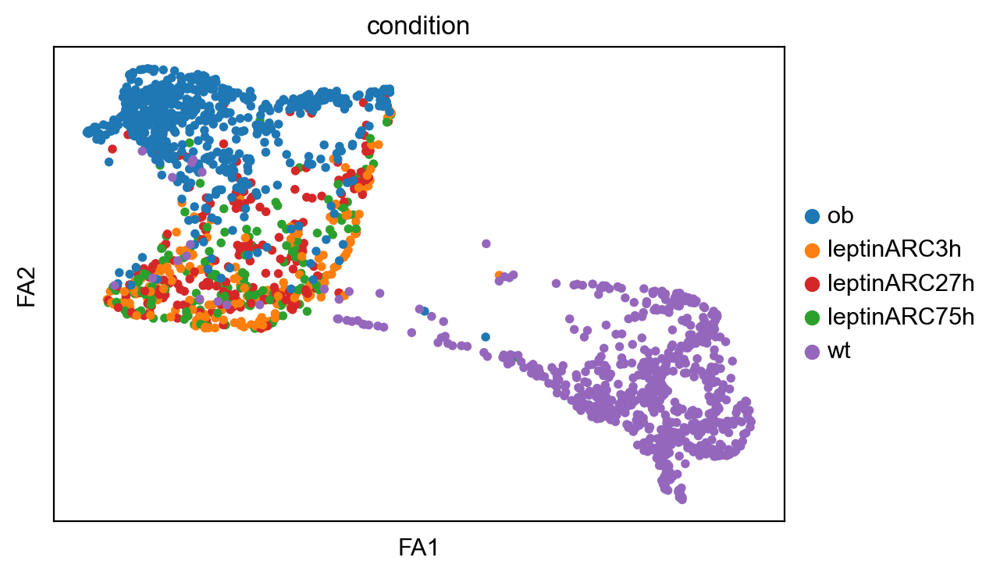

In [50]:
sc.pl.draw_graph(adata_arc_cluster, color=['condition'], save= 'Fig2c_arc_cluster'+ cluster + '_scvelo_pt_condition.pdf')

In [58]:
adata_pvh = sc.read_h5ad(python_data_path+"adata_seurat_PVH_111621_v2_scvelo.h5ad")
stage_order_PVH = ['ob', 'leptinPVH3h', 'leptinPVH27h', 'leptinPVH75h', 'wt']
#stage_color_PVH_dict = dict(ob="#e04516", leptinPVH3h="#cdd781", leptinPVH27h="#B4B415", leptinPVH75h="#f1ca07", wt="#22d062")
stage_PVH_dict = {'ob': 'ob', 'leptinPVH3h': 'leptinPVH3h', 'leptinPVH24h': 'leptinPVH27h', 'leptinPVH72h': 'leptinPVH75h', 'wt': 'wt'}
adata_pvh.obs['condition'] = adata_pvh.obs['condition'].map(stage_PVH_dict)
# make the condition to plot a categorical variable with the correct order
adata_pvh.obs['condition'] = pd.Categorical(adata_pvh.obs['condition'], categories=stage_order_PVH, ordered=True)

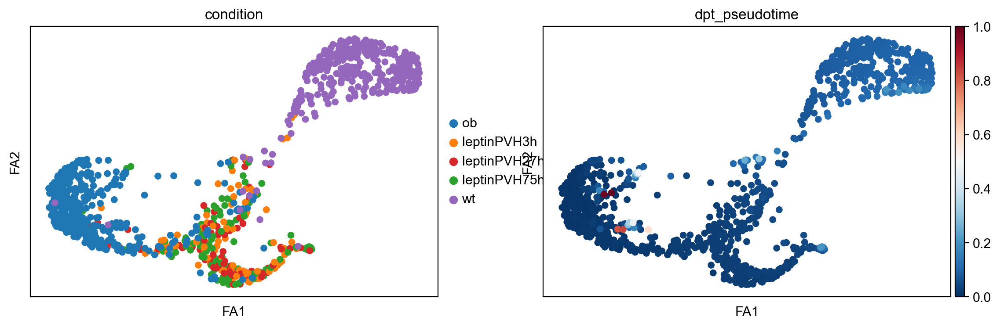

In [62]:
cluster = 3
adata_pvh_sub = adata_pvh[adata_pvh.obs.clusters == cluster]
sc.tl.diffmap(adata_pvh_sub)
sc.pp.neighbors(adata_pvh_sub, n_neighbors=20, use_rep='X_diffmap')
adata_pvh_sub.uns['iroot'] = np.flatnonzero(adata_pvh_sub.obs['condition']  == 'ob')[0]
sc.tl.dpt(adata_pvh_sub)
sc.tl.draw_graph(adata_pvh_sub)
sc.pl.draw_graph(adata_pvh_sub, color=['condition', 'dpt_pseudotime'],
                 palette={'leptinPVH27h': '#d62728', 'leptinPVH3h': '#ff7f0e', 'ob': '#1f77b4', 'leptinPVH75h': '#2ca02c', 'wt': '#9467bd'})

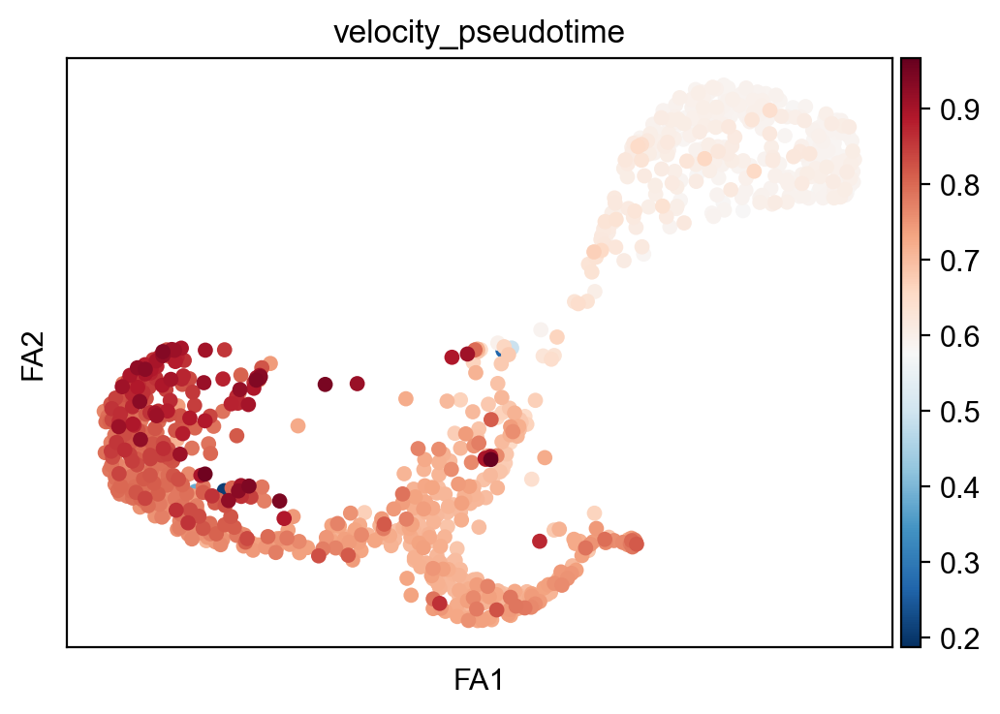

In [63]:
sc.pl.draw_graph(adata_pvh_sub, color=['velocity_pseudotime'], save= 'Fig2c_pvh_cluster'+ str(cluster) + '_scvelo_pt.pdf')

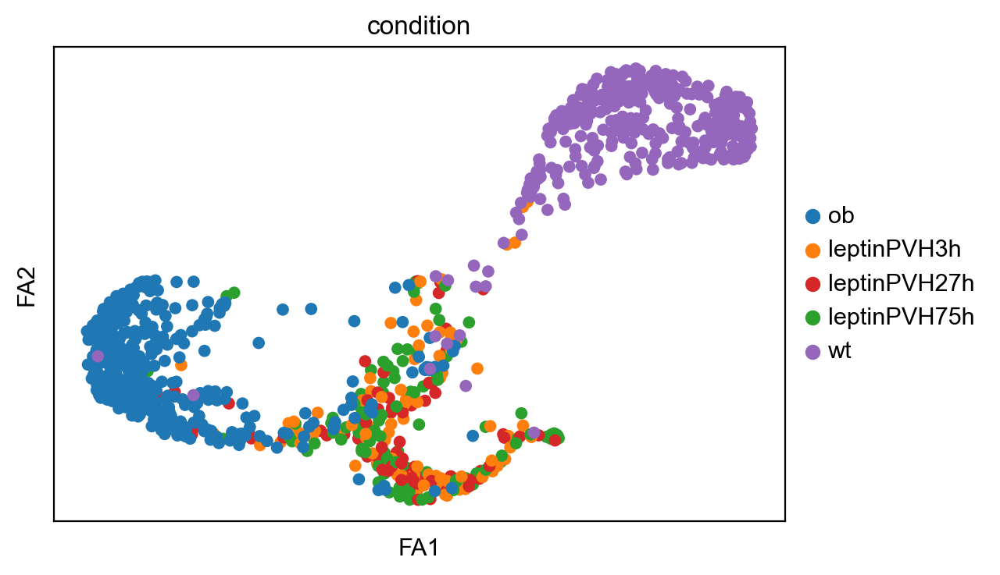

In [64]:
sc.pl.draw_graph(adata_pvh_sub, color=['condition'], save= 'Fig2c_pvh_cluster'+ str(cluster) + '_scvelo_pt_condition.pdf')

### 2d

In [ ]:
# scNeuron environment
# top velocity genes for AGRP and POMC neurons in ARC
adata_arc = sc.read(python_data_path+"adata_seurat_111621_scvelo.h5ad")

computing neighbors
    finished (0:00:01) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing velocities
    finished (0:00:40) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
ranking velocity genes
    finished (0:00:00) --> added 
    'rank_velocity_genes', sorted scores by group ids (adata.uns) 
    'spearmans_score', spearmans correlation scores (adata.var)
Calculating gene-level Spearman correlations for quality control...


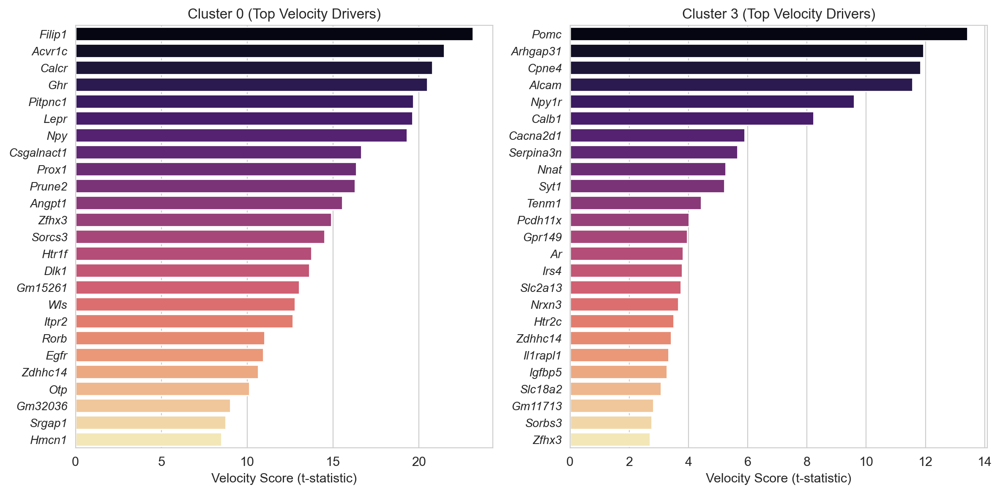

In [29]:
# --- 1. CALCULATE REQUISITE DATA ---
scv.pp.neighbors(adata_arc)
scv.tl.velocity(adata_arc, mode='steady_state')
# We pull more genes (20) to ensure we have high-quality ones after filtering
scv.tl.rank_velocity_genes(adata_arc, groupby='clusters', n_genes=25) 

# --- 2. CALCULATE SPEARMAN FOR FILTERING ---
print("Calculating gene-level Spearman correlations for quality control...")
s_data = adata_arc.layers['spliced'].A.T if hasattr(adata_arc.layers['spliced'], "toarray") else adata_arc.layers['spliced'].T
u_data = adata_arc.layers['unspliced'].A.T if hasattr(adata_arc.layers['unspliced'], "toarray") else adata_arc.layers['unspliced'].T
adata_arc.var['spearmans_score'] = vcorrcoef(s_data, u_data, mode='spearman')

# --- 3. DATA EXTRACTION FUNCTION (TOP VELOCITY) ---
def get_velocity_ranking_df(adata, cluster_id, n_genes=10, min_corr=0.1):
    c_id = str(cluster_id)
    
    # Extract names and the velocity scores (t-statistics)
    top_genes = [name for name in adata.uns['rank_velocity_genes']['names'][c_id]]
    vel_scores = [score for score in adata.uns['rank_velocity_genes']['scores'][c_id]]
    
    # Create DataFrame
    df = pd.DataFrame({
        'Gene': top_genes, 
        'Velocity_Score': vel_scores,
        'Spearman_Score': adata.var.loc[top_genes, 'spearmans_score'].values,
        'Cluster': c_id
    })
    
    # FILTER: Keep only genes with a positive correlation to ensure model fit
    # This removes genes where the velocity might be a math artifact
    df = df[df['Spearman_Score'] > min_corr]
    
    # SORT by Velocity Score (Magnitude)
    df = df.sort_values('Velocity_Score', ascending=False)
    
    return df.head(n_genes)

# Extract for clusters 0 and 3
df0 = get_velocity_ranking_df(adata_arc, '0', n_genes=25)
df3 = get_velocity_ranking_df(adata_arc, '3', n_genes=25)

# --- 4. FINAL BAR PLOT ---
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

plot_data = [df0, df3]
clusters = ['0', '3']

for i, df_subset in enumerate(plot_data):
    sns.barplot(
        data=df_subset, 
        x="Velocity_Score", # Switched to Velocity Score
        y="Gene", 
        ax=axes[i], 
        palette="magma",    # Different palette to distinguish from correlation plot
        width=0.8
    )
    axes[i].set_title(f"Cluster {clusters[i]} (Top Velocity Drivers)")
    axes[i].set_xlabel("Velocity Score (t-statistic)")
    axes[i].set_ylabel("")
    
    # Italicize gene names
    axes[i].set_yticklabels(axes[i].get_yticklabels(), fontstyle='italic', fontsize=10)

plt.tight_layout()
plt.show()

# To save:
# plt.savefig(save_figure_path + 'Fig2/Fig2d_ARC_ranked_velocity_genes.pdf', dpi=400)

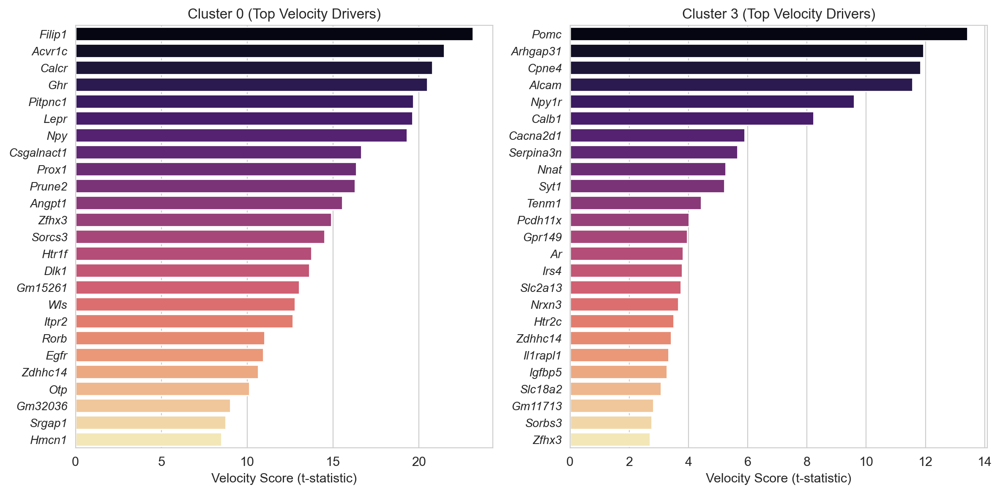

In [30]:
# --- 4. FINAL BAR PLOT ---
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

plot_data = [df0, df3]
clusters = ['0', '3']

for i, df_subset in enumerate(plot_data):
    sns.barplot(
        data=df_subset, 
        x="Velocity_Score", # Switched to Velocity Score
        y="Gene", 
        ax=axes[i], 
        palette="magma",    # Different palette to distinguish from correlation plot
        width=0.8
    )
    axes[i].set_title(f"Cluster {clusters[i]} (Top Velocity Drivers)")
    axes[i].set_xlabel("Velocity Score (t-statistic)")
    axes[i].set_ylabel("")
    
    # Italicize gene names
    axes[i].set_yticklabels(axes[i].get_yticklabels(), fontstyle='italic', fontsize=10)

plt.tight_layout()
#plt.show()

# To save:
plt.savefig(save_figure_path + 'Fig2/Fig2d_ARC_ranked_velocity_genes.pdf', dpi=400)

In [26]:
scv.tl.rank_velocity_genes(adata_arc, groupby='clusters', n_genes=200) 
df0 = get_velocity_ranking_df(adata_arc, '0', n_genes=200)
df3 = get_velocity_ranking_df(adata_arc, '3', n_genes=200)

ranking velocity genes
    finished (0:00:02) --> added 
    'rank_velocity_genes', sorted scores by group ids (adata.uns) 
    'spearmans_score', spearmans correlation scores (adata.var)


In [27]:
# is Otp in df0 or df3?
print("Cluster 0:")
print(df0[df0['Gene'] == 'Otp'])
print("\nCluster 3:")
print(df3[df3['Gene'] == 'Otp'])

Cluster 0:
   Gene  Velocity_Score  Spearman_Score Cluster
21  Otp           10.12        0.146954       0

Cluster 3:
   Gene  Velocity_Score  Spearman_Score Cluster
60  Otp            0.47        0.146954       3


In [87]:
scv.tl.rank_velocity_genes(adata_arc, groupby='clusters', n_genes=200) 
df = scv.get_df(adata_arc, 'rank_velocity_genes/names')


ranking velocity genes
    finished (0:01:33) --> added 
    'rank_velocity_genes', sorted scores by group ids (adata.uns) 
    'spearmans_score', spearmans correlation scores (adata.var)


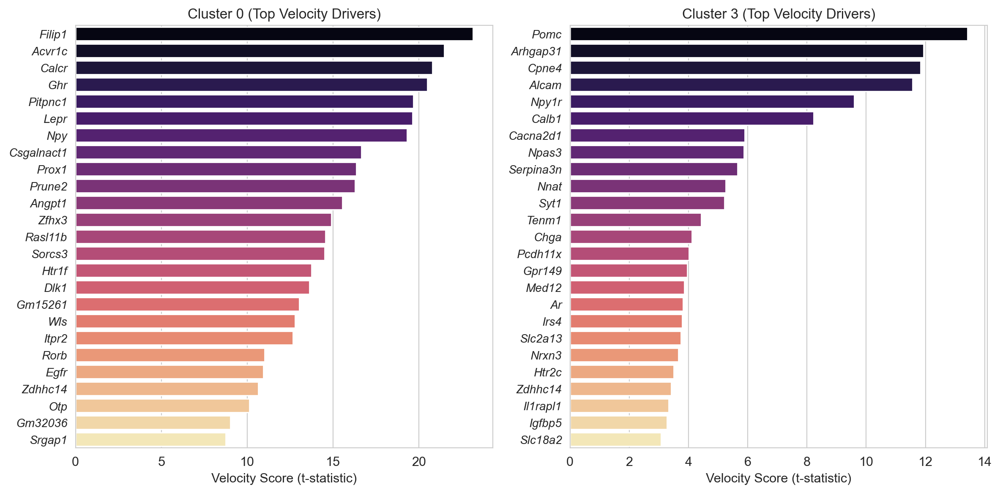

In [93]:
# --- 3. DATA EXTRACTION FUNCTION (TOP VELOCITY) ---
def get_velocity_ranking_df(adata, cluster_id, n_genes=10, min_corr=0.1):
    c_id = str(cluster_id)
    
    # Extract names and the velocity scores (t-statistics)
    top_genes = [name for name in adata.uns['rank_velocity_genes']['names'][c_id]]
    vel_scores = [score for score in adata.uns['rank_velocity_genes']['scores'][c_id]]
    
    # Create DataFrame
    df = pd.DataFrame({
        'Gene': top_genes, 
        'Velocity_Score': vel_scores,
        'Spearman_Score': adata.var.loc[top_genes, 'spearmans_score'].values,
        'Cluster': c_id
    })
    
    # FILTER: Keep only genes with a positive correlation to ensure model fit
    # This removes genes where the velocity might be a math artifact
    df = df[df['Spearman_Score'] > min_corr]
    
    # SORT by Velocity Score (Magnitude)
    df = df.sort_values('Velocity_Score', ascending=False)
    
    return df.head(n_genes)

# Extract for clusters 0 and 3
df0 = get_velocity_ranking_df(adata_arc, '0', n_genes=25)
df3 = get_velocity_ranking_df(adata_arc, '3', n_genes=25)

# --- 4. FINAL BAR PLOT ---
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

plot_data = [df0, df3]
clusters = ['0', '3']

for i, df_subset in enumerate(plot_data):
    sns.barplot(
        data=df_subset, 
        x="Velocity_Score", # Switched to Velocity Score
        y="Gene", 
        ax=axes[i], 
        palette="magma",    # Different palette to distinguish from correlation plot
        width=0.8
    )
    axes[i].set_title(f"Cluster {clusters[i]} (Top Velocity Drivers)")
    axes[i].set_xlabel("Velocity Score (t-statistic)")
    axes[i].set_ylabel("")
    
    # Italicize gene names
    axes[i].set_yticklabels(axes[i].get_yticklabels(), fontstyle='italic', fontsize=10)

plt.tight_layout()
#plt.show()
plt.savefig(save_figure_path + 'Fig2/Fig2d_ARC_ranked_velocity_genes.pdf', dpi=400)

#### save the top velocity genes for ARC 


In [ ]:
# save the top velocity genes for ARC
rank_genes = adata_arc.uns['rank_velocity_genes']

dfs = []
names_df = pd.DataFrame.from_records(rank_genes['names'])
scores_df = pd.DataFrame.from_records(rank_genes['scores'])

for cluster in names_df.columns:
    tmp = pd.DataFrame({
        'cluster': cluster,
        'gene': names_df[cluster],
        'score': scores_df[cluster]
    })
    dfs.append(tmp)

df = pd.concat(dfs, ignore_index=True)

print(df.shape)
df.head()

(5000, 3)


,cluster,gene,score
0,0,Filip1,23.150000
1,0,Acvr1c,21.480000
2,0,Calcr,20.780001
3,0,Ghr,20.480000
4,0,Pitpnc1,19.670000


In [ ]:
df.to_csv(save_obj_path + 'ARC_velocity_genes_top200_053026.csv')

#### save the top velocity genes for PVH

In [ ]:
#### save the top velocity genes for PVH 
adata_pvh = sc.read_h5ad(python_data_path+"adata_seurat_PVH_111621_v2_scvelo.h5ad")
stage_order_PVH = ['ob', 'leptinPVH3h', 'leptinPVH27h', 'leptinPVH75h', 'wt']
#stage_color_PVH_dict = dict(ob="#e04516", leptinPVH3h="#cdd781", leptinPVH27h="#B4B415", leptinPVH75h="#f1ca07", wt="#22d062")
stage_PVH_dict = {'ob': 'ob', 'leptinPVH3h': 'leptinPVH3h', 'leptinPVH24h': 'leptinPVH27h', 'leptinPVH72h': 'leptinPVH75h', 'wt': 'wt'}
adata_pvh.obs['condition'] = adata_pvh.obs['condition'].map(stage_PVH_dict)
# make the condition to plot a categorical variable with the correct order
adata_pvh.obs['condition'] = pd.Categorical(adata_pvh.obs['condition'], categories=stage_order_PVH, ordered=True)

In [154]:
scv.tl.rank_velocity_genes(
    adata_pvh,
    groupby='clusters',
    n_genes=200
)
rank_genes = adata_pvh.uns['rank_velocity_genes']
dfs = []
names_df = pd.DataFrame.from_records(rank_genes['names'])
scores_df = pd.DataFrame.from_records(rank_genes['scores'])

for cluster in names_df.columns:
    tmp = pd.DataFrame({
        'cluster': cluster,
        'gene': names_df[cluster],
        'score': scores_df[cluster]
    })
    dfs.append(tmp)

df = pd.concat(dfs, ignore_index=True)

print(df.shape)
df.head()

ranking velocity genes
    finished (0:01:18) --> added 
    'rank_velocity_genes', sorted scores by group ids (adata.uns) 
    'spearmans_score', spearmans correlation scores (adata.var)
(4275, 3)


,cluster,gene,score
0,0,Hmcn1,11.76
1,0,Dlx6os1,10.40
2,0,Ptprz1,10.10
3,0,Gad2,8.32
4,0,Lrtm1,8.13


In [155]:
df.to_csv(save_obj_path + 'PVH_velocity_genes_top200_053026.csv')

### 2e

In [ ]:
# 1. Extract the ranking dataframe
df = scv.get_df(adata_arc, 'rank_velocity_genes/names')

# 2. Define your backbone settings
# We remove add_outline since we are only showing one cluster anyway
kwargs = dict(
    frameon=False, 
    size=40, 
    linewidth=1.5,
    legend_loc='right margin'
)

# 3. Plot for Cluster 0: Top 5 genes, showing ONLY Cluster 0 cells
scv.pl.scatter(
    adata_arc, 
    basis=df['0'][:5], 
    groups='0',         # <--- This restricts the plot to only Cluster 0
    ylabel='Cluster 0', 
    color='velocity', 
    save=save_figure_path + 'Fig2/Fig2e_cluster_0_top_velocity.pdf',
    **kwargs
)

# 4. Plot for Cluster 3: Top 5 genes, showing ONLY Cluster 3 cells
scv.pl.scatter(
    adata_arc, 
    basis=df['3'][:5], 
    groups='3',         # <--- This restricts the plot to only Cluster 3
    ylabel='Cluster 3', 
    color='velocity',
    save=save_figure_path + 'Fig2/Fig2e_cluster_3_top_velocity.pdf', 
    **kwargs
)

### 2f

In [ ]:
# visualize Npy and Opt expression in the velocity space for cluster 0 and 3
# 1. Extract the ranking dataframe

scv.pp.neighbors(adata_arc)
scv.tl.velocity(adata_arc, mode='steady_state')

In [ ]:

# 2. Define your backbone settings
# We remove add_outline since we are only showing one cluster anyway
kwargs = dict(
    frameon=False, 
    size=40, 
    linewidth=1.5,
    legend_loc='right margin',
    color_map='magma'
)

genes = ['Npy', 'Otp']

scv.pl.scatter(
    adata_arc, 
    basis=genes, 
    groups='0',         # <--- This restricts the plot to only Cluster 0
    ylabel='Cluster 0', 
    color='velocity',
    save=save_figure_path + 'Fig2/Fig2f_cluster_0__Npy_Otp_velocity.pdf',
    **kwargs
)

# 4. Plot for Cluster 3: Top 5 genes, showing ONLY Cluster 3 cells
scv.pl.scatter(
    adata_arc, 
    basis=genes, 
    groups='3',         # <--- This restricts the plot to only Cluster 3
    ylabel='Cluster 3', 
    color='velocity',
    save=save_figure_path + 'Fig2/Fig2f_cluster_3_Npy_Otp_velocity.pdf', 
    **kwargs
)

# Figure 5

### 5a

In [ ]:
adata_pvh = sc.read_h5ad(python_data_path+"adata_seurat_PVH_111621_v2_scvelo.h5ad")
stage_order_PVH = ['ob', 'leptinPVH3h', 'leptinPVH27h', 'leptinPVH75h', 'wt']
#stage_color_PVH_dict = dict(ob="#e04516", leptinPVH3h="#cdd781", leptinPVH27h="#B4B415", leptinPVH75h="#f1ca07", wt="#22d062")
stage_PVH_dict = {'ob': 'ob', 'leptinPVH3h': 'leptinPVH3h', 'leptinPVH24h': 'leptinPVH27h', 'leptinPVH72h': 'leptinPVH75h', 'wt': 'wt'}
adata_pvh.obs['condition'] = adata_pvh.obs['condition'].map(stage_PVH_dict)
# make the condition to plot a categorical variable with the correct order
adata_pvh.obs['condition'] = pd.Categorical(adata_pvh.obs['condition'], categories=stage_order_PVH, ordered=True)

In [72]:
scv.tl.differential_kinetic_test(adata_pvh, var_names=['Nova1'], groupby='clusters')

testing for differential kinetics
    finished (0:00:00) --> added 
    'fit_diff_kinetics', clusters displaying differential kinetics (adata.var)
    'fit_pvals_kinetics', p-values of differential kinetics (adata.var)

outputs model fit of gene: Nova1


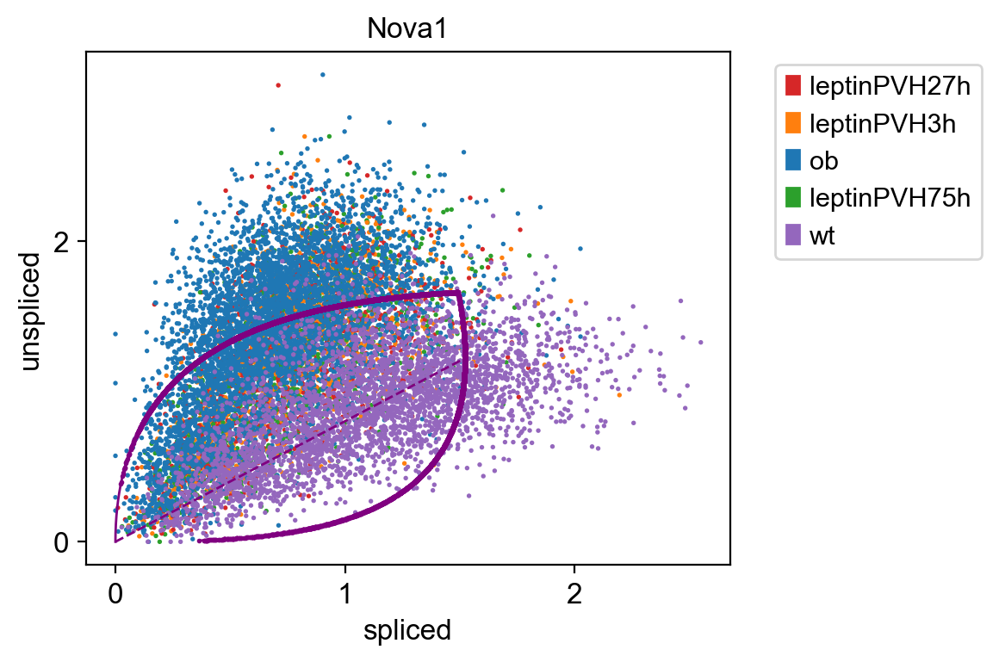

In [79]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

palette = {
    'leptinPVH27h': '#d62728',
    'leptinPVH3h': '#ff7f0e',
    'ob': '#1f77b4',
    'leptinPVH75h': '#2ca02c',
    'wt': '#9467bd'
}

scv.pl.scatter(
    adata_pvh,
    basis='Nova1',
    add_outline='fit_diff_kinetics',
    color='condition',
    palette=palette,
    show=False
)

handles = [Patch(color=v, label=k) for k, v in palette.items()]
plt.legend(handles=handles, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(save_figure_path +'Fig5/Fig5a_pvh_nova1_velocity_by_condition.pdf')
#plt.show()